# Entregas tardías, satisfacción y Pareto de Olist

**Caso integrador · Analytics Essentials I · R**

**Pregunta de negocio:** ¿Qué categorías, regiones o vendedores concentran entregas tardías y calificaciones bajas? ¿Qué papel tiene la distancia y dónde conviene iniciar una acción operativa?

El objetivo es construir una vista a nivel de pedido, identificar patrones de insatisfacción y convertirlos en una primera lista de investigación. Seguimos la secuencia de `Pregunta1.ipynb` y `Pregunta3_Gustavo.ipynb`: cargar, revisar, preparar, agregar, unir, validar y después analizar.

Conservamos el criterio del equipo: **compras de enero de 2017 a agosto de 2018**, pedidos entregados y **promedio de reseñas por pedido**. Las comparaciones de satisfacción requieren calificación disponible. Se incluye un perfil alternativo para toda la ventana del ZIP y última reseña, de manera que los cambios de criterio queden explícitos.

Las relaciones se interpretan como asociaciones históricas. Un ranking o una correlación no demuestra responsabilidad individual ni el efecto causal de una intervención.

## Cómo ejecutar este notebook

1. Guarda este `.ipynb` en `notebooks/` del repositorio `santiago-1710/Caso-Integrador-Final`. Es un archivo adicional; no reemplaza el trabajo de otro integrante.
2. Elige un entorno **R**, igual que en el notebook de Gustavo. En Colab, sube el ZIP original desde el panel **Archivos** antes de ejecutar. En Jupyter local, utiliza el kernel R/IRkernel.
3. Coloca los nueve CSV en `data/olist/`, o el ZIP original en la raíz del proyecto, `data/` o `/content` en Colab. Puedes indicar la ruta exacta del ZIP en `ruta_zip_manual`.
4. Ejecuta las celdas de arriba abajo. La primera instala los paquetes que falten. No se mezclan celdas de Python con R.
5. Las tablas y gráficos se guardan en `salidas/pareto_olist_R/<perfil>/`. Los resultados de distintos perfiles quedan separados.
6. Para cambiar un criterio, edita la configuración y vuelve a ejecutar todo el notebook. Las tablas, gráficos y conclusiones se recalculan.

Los CSV originales no están incluidos en este notebook. El `.gitignore` del repositorio excluye `data/olist/*.csv`; abrir el archivo desde GitHub no proporciona automáticamente los datos. GitHub permite ver las salidas guardadas, pero no ejecuta R.

## 0. Preparación del entorno

Usamos los paquetes de preparación y visualización del equipo. Añadimos `geosphere` para calcular distancias sobre WGS84, `jsonlite` para registrar la configuración, `svglite` para guardar gráficos vectoriales y `sandwich` para la comparación ajustada opcional.

La instalación solo se realiza si falta un paquete. No actualizamos automáticamente versiones ya instaladas ni modificamos `renv.lock`. Al final se guarda `sessionInfo()` para conocer las versiones utilizadas.

In [2]:
# 0.1 Bibliotecas -----------------------------------------------------------
paquetes <- c("readr", "dplyr", "tidyr", "stringr", "lubridate", "ggplot2",
              "purrr", "scales", "geosphere", "jsonlite", "svglite", "sandwich")
faltantes <- paquetes[!vapply(paquetes, requireNamespace, logical(1), quietly = TRUE)]
if (length(faltantes) > 0) {
  install.packages(faltantes, repos = "https://cloud.r-project.org")
}
suppressPackageStartupMessages(invisible(lapply(paquetes, library, character.only = TRUE)))
options(scipen = 999, width = 120, digits = 4)
theme_set(theme_minimal(base_size = 12))
cat("Entorno R listo.\n", R.version.string, "\n")

Entorno R listo.
 R version 4.6.1 (2026-06-24 ucrt) 


### 0.2 Funciones para presentar y guardar resultados

Las funciones siguientes evitan repetir instrucciones. `numero()` y `porcentaje()` solo cambian la presentación; los cálculos conservan valores numéricos. `mostrar()` imprime tablas completas y `guardar_grafico()` guarda el mismo gráfico que se muestra en el notebook.

Se usa SVG para preservar etiquetas y facilitar la lectura al ampliar. Cada figura tiene un título y un denominador o criterio de selección.

In [3]:
numero <- function(x, decimales = 1) {
  formatC(x, format = "f", digits = decimales, big.mark = ".", decimal.mark = ",")
}
porcentaje <- function(x, decimales = 1) paste0(numero(100 * x, decimales), "%")
mostrar <- function(x, filas = NULL) {
  if (!is.null(filas)) x <- head(x, filas)
  presentacion <- as.data.frame(x)
  if ("p" %in% names(presentacion)) {
    presentacion$p <- format.pval(presentacion$p, digits = 3, eps = .0001)
  }
  print(presentacion, row.names = FALSE)
  invisible(x)
}
mediana_valida <- function(x) if (all(is.na(x))) NA_real_ else median(x, na.rm = TRUE)
media_valida <- function(x) if (all(is.na(x))) NA_real_ else mean(x, na.rm = TRUE)
guardar_grafico <- function(grafico, nombre, ancho = 10, alto = 6) {
  archivo <- file.path(ruta_salida, paste0(nombre, ".svg"))
  ggsave(archivo, plot = grafico, device = svglite::svglite,
         width = ancho, height = alto, bg = "white")
  print(grafico)
  ultimo_grafico <<- archivo
  invisible(archivo)
}
ultimo_grafico <- ""

## 1. Configuración y decisiones del análisis

El perfil `equipo` usa el período del proyecto y promedio de reseñas. El final es exclusivo: `< 2018-09-01` incluye todo el 31 de agosto. El perfil `exploracion_completa` usa toda la ventana de archivos y la última reseña, reproduciendo el criterio del análisis anterior del chat.

`min_pedidos_correlacion` filtra la matriz, no el Pareto. El Pareto debe conservar todos los vendedores presentes en los pedidos analizados. Los umbrales de preparación y tránsito son reglas exploratorias editables, no estándares contractuales. La comparación ajustada es un complemento que puede demorar más que el resto del notebook.

In [4]:
# 1.1 Parámetros que puede modificar el equipo ------------------------------
perfil <- "equipo"  # Alternativa: "exploracion_completa"
vendedor_objetivo <- "7c67e1448b00f6e969d365cea6b010ab"
min_pedidos_correlacion <- 100L
umbral_preparacion_dias <- 5
umbral_transito_dias <- 15
ejecutar_modelo <- TRUE
ruta_zip_manual <- ""  # Opcional: ruta exacta al ZIP original.
ruta_csv_manual <- ""  # Opcional: carpeta con los nueve CSV.

if (perfil == "equipo") {
  fecha_inicio <- as.Date("2017-01-01")
  fecha_fin <- as.Date("2018-09-01")
  regla_resenas <- "promedio"
} else if (perfil == "exploracion_completa") {
  fecha_inicio <- as.Date(NA)
  fecha_fin <- as.Date(NA)
  regla_resenas <- "ultima"
} else stop("Perfil no reconocido.")
raiz_proyecto <- if (basename(getwd()) == "notebooks") ".." else "."
ruta_salida <- file.path(raiz_proyecto, "salidas", "pareto_olist_R", perfil)
dir.create(ruta_salida, recursive = TRUE, showWarnings = FALSE)
mostrar(tibble(perfil, fecha_inicio, fin_exclusivo = fecha_fin, regla_resenas,
               min_pedidos_correlacion, ejecutar_modelo))

 perfil fecha_inicio fin_exclusivo regla_resenas min_pedidos_correlacion ejecutar_modelo
 equipo   2017-01-01    2018-09-01      promedio                     100            TRUE


## 2. Carga de datos: qué aporta cada archivo

Antes de transformar, necesitamos saber qué representa cada fila. Un pedido puede tener varios artículos, pagos, vendedores y reseñas. Por eso no es correcto unir todo directamente y después contar filas como si fueran pedidos.

| Tabla | Información que aporta | Unidad original |
|---|---|---|
| `orders` | Estado y fechas de compra, despacho y entrega | Un pedido |
| `items` | Producto, vendedor, precio y flete | Un artículo de pedido |
| `reviews` | Nota, comentario y fecha de respuesta | Una reseña |
| `customers` | Ciudad, estado y prefijo del cliente | Un ID de cliente del pedido |
| `sellers` | Ciudad, estado y prefijo del vendedor | Un vendedor |
| `products` | Categoría, peso y dimensiones | Un producto |
| `geolocation` | Coordenadas de prefijos postales | Una observación geográfica |
| `payments` | Importe, tipo de pago y cuotas | Un pago |
| `translation` | Traducción de categorías | Una categoría |

Los identificadores y prefijos se leen inicialmente como texto. Así no se pierden ceros iniciales. Los tipos numéricos se convierten explícitamente más adelante.

In [5]:
# 2.1 Encontrar CSV completos o un ZIP original válido -----------------------
archivos <- c(orders = "olist_orders_dataset.csv",
  items = "olist_order_items_dataset.csv", reviews = "olist_order_reviews_dataset.csv",
  customers = "olist_customers_dataset.csv", sellers = "olist_sellers_dataset.csv",
  products = "olist_products_dataset.csv", geolocation = "olist_geolocation_dataset.csv",
  payments = "olist_order_payments_dataset.csv",
  translation = "product_category_name_translation.csv")
carpetas <- unique(c(ruta_csv_manual, "../data/olist", "data/olist", "data", "../data",
                     "/content", "."))
carpetas <- carpetas[nzchar(carpetas) & dir.exists(carpetas)]
carpetas_completas <- carpetas[vapply(carpetas, function(p) {
  all(file.exists(file.path(p, unname(archivos))))
}, logical(1))]
es_zip_olist <- function(z) tryCatch({
  nombres <- basename(utils::unzip(z, list = TRUE)$Name)
  all(vapply(unname(archivos), function(a) sum(nombres == a) == 1L, logical(1)))
}, error = function(e) FALSE)

if (nzchar(ruta_csv_manual) && !nzchar(ruta_zip_manual)) {
  if (!all(file.exists(file.path(ruta_csv_manual, unname(archivos))))) {
    stop("La carpeta indicada no contiene los nueve CSV originales.")
  }
  ruta_datos <- ruta_csv_manual
  fuente_datos <- paste("CSV locales:", ruta_datos)
} else if (length(carpetas_completas) > 0 && !nzchar(ruta_zip_manual)) {
  ruta_datos <- carpetas_completas[1]
  fuente_datos <- paste("CSV locales:", ruta_datos)
} else {
  zips <- if (nzchar(ruta_zip_manual)) ruta_zip_manual else unique(unlist(lapply(
    carpetas, list.files, pattern = "\\.zip$", full.names = TRUE, ignore.case = TRUE)))
  zips <- zips[vapply(zips, es_zip_olist, logical(1))]
  zips <- unique(normalizePath(zips, mustWork = FALSE))
  if (length(zips) == 0) stop("Faltan datos. Sube el ZIP original al panel Archivos o coloca los CSV en data/olist/.")
  if (length(zips) > 1) stop("Hay varios ZIP válidos. Especifica ruta_zip_manual.")
  indice <- utils::unzip(zips[1], list = TRUE)$Name
  entradas <- vapply(unname(archivos), function(a) indice[basename(indice) == a], character(1))
  ruta_datos <- tempfile("olist_pareto_")
  dir.create(ruta_datos)
  utils::unzip(zips[1], files = unname(entradas), exdir = ruta_datos, junkpaths = TRUE)
  fuente_datos <- paste("ZIP original:", basename(zips[1]))
}
cat("Fuente utilizada:", fuente_datos, "\n")

Fuente utilizada: CSV locales: ../data/olist 


### 2.2 Leer sin transformar todavía

En esta celda únicamente cargamos las tablas. La selección de una sola fuente completa evita mezclar accidentalmente CSV de distintas versiones. Se fija un hilo de lectura para conservar compatibilidad entre R local, Colab y la validación en WebR.

In [6]:
tablas <- purrr::map(archivos, function(a) readr::read_csv(
  file.path(ruta_datos, a), col_types = cols(.default = col_character()),
  show_col_types = FALSE, progress = FALSE, num_threads = 1))
cat("Se cargaron", length(tablas), "tablas originales.\n")

Se cargaron 9 tablas originales.


## 3. Revisión inicial: tamaño, nulos y granularidad

Primero revisamos dimensiones y duplicados exactos. Después contamos claves distintas para reconocer tablas que contienen detalle legítimo. Que `order_id` se repita en artículos no es un error: puede representar varios productos del mismo pedido.

Los nulos en comentarios son habituales y no se utilizan para inventar una nota. La ausencia de fecha de entrega también puede corresponder a un pedido que no se entregó; no se convierte automáticamente en retraso.

In [7]:
# 3.1 Diagnóstico general antes de transformar -------------------------------
diagnostico <- purrr::imap_dfr(tablas, function(df, nombre) {
  tibble(tabla = nombre, filas = nrow(df), columnas = ncol(df),
    celdas_nulas = sum(is.na(df)), duplicados_exactos = sum(duplicated(df)))
})
nulos_por_columna <- purrr::imap_dfr(tablas, function(df, nombre) {
  tibble(tabla = nombre, columna = names(df), nulos = vapply(df, function(x) sum(is.na(x)), integer(1)))
})
granularidad <- tibble(tabla = c("orders", "items", "reviews", "payments"),
  filas = c(nrow(tablas$orders), nrow(tablas$items), nrow(tablas$reviews), nrow(tablas$payments)),
  pedidos_distintos = c(n_distinct(tablas$orders$order_id), n_distinct(tablas$items$order_id),
    n_distinct(tablas$reviews$order_id), n_distinct(tablas$payments$order_id)))
mostrar(diagnostico)
mostrar(granularidad)
mostrar(nulos_por_columna %>% filter(nulos > 0))

       tabla   filas columnas celdas_nulas duplicados_exactos
      orders   99441        8         4908                  0
       items  112650        7            0                  0
     reviews   99224        7       145914                  0
   customers   99441        5            0                  0
     sellers    3095        4            0                  0
    products   32951        9         2448                  0
 geolocation 1000163        5            0             261831
    payments  103886        5            0                  0
 translation      71        2            0                  0
    tabla  filas pedidos_distintos
   orders  99441             99441
    items 112650             98666
  reviews  99224             98673
 payments 103886             99440
    tabla                       columna nulos
   orders             order_approved_at   160
   orders  order_delivered_carrier_date  1783
   orders order_delivered_customer_date  2965
  reviews          re

### 3.2 Estandarizar tipos y comprobar relaciones

Quitamos solo filas completamente repetidas en las tablas de negocio. En geolocalización conservamos las observaciones repetidas: no existe una clave que permita afirmar que son errores y así mantenemos el criterio de las medianas del análisis anterior. Interpretamos las marcas de tiempo con una zona común (`UTC`) para hacer diferencias consistentes; esto no convierte las horas de cada estado a su zona local. La definición de retraso usa los días que figuran en los datos, como en el proyecto.

Las comprobaciones detienen la ejecución si una clave que debe ser única se repite, si aparecen importes negativos o si una relación apunta a un ID inexistente. Así evitamos presentar resultados aparentemente válidos sobre una unión incorrecta.

In [8]:
# 3.2 Limpieza controlada ---------------------------------------------------
tablas <- purrr::imap(tablas, function(df, nombre) {
  if (nombre == "geolocation") df else distinct(df)
})
parsear_numero <- function(x, nombre) {
  y <- suppressWarnings(readr::parse_double(x))
  if (any(!is.na(x) & is.na(y))) stop("Número no interpretable en ", nombre)
  y
}
parsear_fecha <- function(x, nombre) {
  y <- lubridate::ymd_hms(x, quiet = TRUE, tz = "UTC")
  if (any(!is.na(x) & is.na(y))) stop("Fecha no interpretable en ", nombre)
  y
}
numericas <- list(items = c("order_item_id", "price", "freight_value"),
  reviews = "review_score", geolocation = c("geolocation_lat", "geolocation_lng"),
  payments = c("payment_sequential", "payment_installments", "payment_value"),
  products = c("product_weight_g", "product_length_cm", "product_height_cm", "product_width_cm"))
for (nombre in names(numericas)) for (columna in numericas[[nombre]]) {
  tablas[[nombre]][[columna]] <- parsear_numero(tablas[[nombre]][[columna]], paste(nombre, columna))
}
for (nombre in c("orders", "reviews", "items")) {
  columnas_fecha <- names(tablas[[nombre]])[grepl("(_date|_timestamp)$|^order_approved_at$", names(tablas[[nombre]]))]
  for (columna in columnas_fecha) {
    tablas[[nombre]][[columna]] <- parsear_fecha(tablas[[nombre]][[columna]], paste(nombre, columna))
  }
}
orders <- tablas$orders %>% mutate(order_status = str_to_lower(str_squish(order_status)))
items <- tablas$items; reviews <- tablas$reviews; customers <- tablas$customers
sellers <- tablas$sellers; products <- tablas$products; geolocation <- tablas$geolocation
payments <- tablas$payments; translation <- tablas$translation
stopifnot(!anyNA(orders$order_id), !anyDuplicated(orders$order_id),
  !anyDuplicated(customers$customer_id), !anyDuplicated(sellers$seller_id),
  !anyDuplicated(products$product_id), !anyDuplicated(items[c("order_id", "order_item_id")]),
  all(items$order_id %in% orders$order_id), all(reviews$order_id %in% orders$order_id),
  all(items$seller_id %in% sellers$seller_id), all(items$product_id %in% products$product_id),
  all(items$price >= 0), all(items$freight_value >= 0),
  all(is.na(reviews$review_score) | between(reviews$review_score, 1, 5)))
cat("Tipos y claves comprobados. Los CSV originales permanecen sin modificar.\n")

Tipos y claves comprobados. Los CSV originales permanecen sin modificar.


## 4. Preparación a nivel de pedido

Antes de unir, agregamos cada tabla que tiene varias filas por pedido. Sumar precios y fletes después de unir artículos con reseñas podría multiplicar los importes. En cambio, resumir primero permite mantener una fila por orden y conciliar totales.

### 4.1 Artículos, categorías y vendedores

Se suma el valor de productos, sin flete, y el flete asignado a artículos. Se cuentan artículos, vendedores y categorías distintos. Los puentes pedido–vendedor y pedido–categoría se conservan para rankings posteriores. Un pedido mixto se marca como tal; no elegimos arbitrariamente un responsable único.

In [9]:
items_producto <- items %>% left_join(products %>% select(product_id, product_category_name),
  by = "product_id", relationship = "many-to-one") %>%
  mutate(categoria = coalesce(product_category_name, "sin_categoria"))
puente_vendedor <- items %>% distinct(order_id, seller_id)
puente_categoria <- items_producto %>% distinct(order_id, categoria)
items_orden <- items_producto %>% group_by(order_id) %>% summarise(
  valor_productos = sum(price), flete = sum(freight_value), n_items = n(),
  n_vendedores = n_distinct(seller_id), n_categorias = n_distinct(categoria),
  vendedor_unico = if (n_distinct(seller_id) == 1) first(seller_id) else NA_character_,
  categoria_orden = if (n_distinct(categoria) == 1) first(categoria) else "multiples_categorias",
  .groups = "drop")
stopifnot(!anyDuplicated(items_orden$order_id),
  isTRUE(all.equal(sum(items$price), sum(items_orden$valor_productos))),
  isTRUE(all.equal(sum(items$freight_value), sum(items_orden$flete))))
mostrar(items_orden, 5)

                         order_id valor_productos flete n_items n_vendedores n_categorias
 00010242fe8c5a6d1ba2dd792cb16214           58.90 13.29       1            1            1
 00018f77f2f0320c557190d7a144bdd3          239.90 19.93       1            1            1
 000229ec398224ef6ca0657da4fc703e          199.00 17.87       1            1            1
 00024acbcdf0a6daa1e931b038114c75           12.99 12.79       1            1            1
 00042b26cf59d7ce69dfabb4e55b4fd9          199.90 18.14       1            1            1
                   vendedor_unico    categoria_orden
 48436dade18ac8b2bce089ec2a041202         cool_stuff
 dd7ddc04e1b6c2c614352b383efe2d36           pet_shop
 5b51032eddd242adc84c38acab88f23d   moveis_decoracao
 9d7a1d34a5052409006425275ba1c2b4         perfumaria
 df560393f3a51e74553ab94004ba5c87 ferramentas_jardim


### 4.2 Reseñas: promedio y alternativas

Siguiendo al equipo, la satisfacción principal es el promedio de `review_score` de cada pedido. Conservamos además la primera y la última nota para medir sensibilidad. La última se determina por fecha de respuesta, fecha de creación e ID como desempate.

`review_id` puede aparecer asociado a distintos pedidos; no se elimina una reseña solo por repetir ese ID en otro pedido. La comprobación relevante para duplicados de reseña es la pareja pedido–reseña.

La última fecha de respuesta se usa como diagnóstico temporal. Si se promedian varias reseñas, esa fecha no describe necesariamente cuándo se emitió cada una de las opiniones que integran el promedio.

In [10]:
stopifnot(!anyDuplicated(reviews[c("order_id", "review_id")]))
reviews_ordenadas <- reviews %>% arrange(order_id, review_answer_timestamp,
                                        review_creation_date, review_id)
ultima_resena <- reviews_ordenadas %>% group_by(order_id) %>% slice_tail(n = 1) %>% ungroup() %>%
  select(order_id, nota_ultima = review_score, ultima_respuesta = review_answer_timestamp)
primera_resena <- reviews_ordenadas %>% group_by(order_id) %>% slice_head(n = 1) %>% ungroup() %>%
  select(order_id, nota_primera = review_score)
reviews_orden <- reviews %>% group_by(order_id) %>% summarise(
  nota_promedio = media_valida(review_score), n_reviews = n(), .groups = "drop") %>%
  left_join(ultima_resena, by = "order_id", relationship = "one-to-one") %>%
  left_join(primera_resena, by = "order_id", relationship = "one-to-one") %>%
  mutate(satisfaccion = if (regla_resenas == "promedio") nota_promedio else nota_ultima)
stopifnot(!anyDuplicated(reviews_orden$order_id))
mostrar(reviews_orden %>% filter(n_reviews > 1) %>%
  select(order_id, n_reviews, nota_promedio, nota_primera, nota_ultima, satisfaccion), 8)

                         order_id n_reviews nota_promedio nota_primera nota_ultima satisfaccion
 0035246a40f520710769010f752e7507         2           5.0            5           5          5.0
 013056cfe49763c6f66bda03396c5ee3         2           4.5            5           4          4.5
 0176a6846bcb3b0d3aa3116a9a768597         2           5.0            5           5          5.0
 02355020fd0a40a0d56df9f6ff060413         2           2.0            3           1          2.0
 029863af4b968de1e5d6a82782e662f5         2           4.5            5           4          4.5
 02e0b68852217f5715fb9cc885829454         2           4.0            4           4          4.0
 02e723e8edb4a123d414f56cc9c4665e         2           5.0            5           5          5.0
 03515a836bb855b03f7df9dee520a8fc         2           5.0            5           5          5.0


### 4.3 Pagos y construcción de la vista

Un pedido también puede tener varios pagos. Sumamos su importe y conservamos el máximo de cuotas. El tipo de pago se toma del pago de mayor importe como descripción, no como explicación causal de satisfacción.

Partimos de `orders`. Después de cada unión comprobamos que el número de filas siga siendo el número original de pedidos y que `order_id` continúe siendo único. Los `left_join` conservan pedidos sin reseña, para que su ausencia sea visible antes de construir la cohorte.

In [11]:
pagos_orden <- payments %>% group_by(order_id) %>% summarise(
  pago_total = sum(payment_value), cuotas = max(payment_installments), .groups = "drop")
tipo_pago <- payments %>% arrange(payment_value) %>% group_by(order_id) %>%
  slice_tail(n = 1) %>% ungroup() %>% select(order_id, payment_type)
pagos_orden <- pagos_orden %>% left_join(tipo_pago, by = "order_id", relationship = "one-to-one")
vista_orden <- orders %>% left_join(customers, by = "customer_id", relationship = "many-to-one")
validar_vista <- function(df) {
  stopifnot(nrow(df) == nrow(orders), !anyDuplicated(df$order_id)); invisible(df)
}
validar_vista(vista_orden)
for (tabla in list(items_orden, reviews_orden, pagos_orden)) {
  vista_orden <- vista_orden %>% left_join(tabla, by = "order_id", relationship = "one-to-one")
  validar_vista(vista_orden)
}
mostrar(vista_orden %>% summarise(filas = n(), pedidos_unicos = n_distinct(order_id),
  sin_items = sum(is.na(n_items)), sin_resena = sum(is.na(satisfaccion)),
  varias_resenas = sum(n_reviews > 1, na.rm = TRUE)))

 filas pedidos_unicos sin_items sin_resena varias_resenas
 99441          99441       775        768            547


## 5. Distancia geodésica entre vendedor y cliente

### 5.1 Preparar coordenadas por prefijo y estado

Un prefijo postal tiene muchas observaciones de coordenadas. Usamos su mediana para reducir la influencia de observaciones extremas y unimos por **prefijo y estado**, no por prefijo solo.

Se excluyen coordenadas fuera de un rectángulo que contiene Brasil: latitud entre −34 y 6 y longitud entre −74 y −34. Es una comprobación amplia de plausibilidad, no una validación contra el límite oficial del país. No inventamos coordenadas cuando falta una coincidencia.

In [12]:
# 5.1 Coordenadas representativas ------------------------------------------
geo_valida <- geolocation %>% filter(between(geolocation_lat, -34, 6),
                                    between(geolocation_lng, -74, -34))
coordenadas <- geo_valida %>% group_by(geolocation_zip_code_prefix, geolocation_state) %>%
  summarise(lat = median(geolocation_lat), lon = median(geolocation_lng), .groups = "drop")
coord_cliente <- customers %>% left_join(coordenadas %>% rename(
  customer_zip_code_prefix = geolocation_zip_code_prefix, customer_state = geolocation_state,
  lat_cliente = lat, lon_cliente = lon),
  by = c("customer_zip_code_prefix", "customer_state"), relationship = "many-to-one")
coord_vendedor <- sellers %>% left_join(coordenadas %>% rename(
  seller_zip_code_prefix = geolocation_zip_code_prefix, seller_state = geolocation_state,
  lat_vendedor = lat, lon_vendedor = lon),
  by = c("seller_zip_code_prefix", "seller_state"), relationship = "many-to-one")
cat("Observaciones geográficas originales:", nrow(geolocation),
    "| Excluidas por coordenadas:", nrow(geolocation) - nrow(geo_valida), "\n")

Observaciones geográficas originales: 1000163 | Excluidas por coordenadas: 42 


### 5.2 Calcular la distancia sobre WGS84

`geosphere::distGeo()` devuelve la distancia más corta sobre el elipsoide WGS84 en metros. El orden de entrada es **longitud, latitud**. Convertimos a kilómetros.

Esta distancia entre zonas postales no equivale a kilómetros recorridos por carretera: no conocemos la ruta ni el transportista. En pedidos con varios vendedores tomamos la máxima distancia para representar la ruta más larga. Si falta una ruta, la distancia del pedido queda ausente; los cálculos no geográficos conservan ese pedido.

In [13]:
rutas <- puente_vendedor %>%
  left_join(orders %>% select(order_id, customer_id), by = "order_id", relationship = "many-to-one") %>%
  left_join(coord_cliente %>% select(customer_id, lat_cliente, lon_cliente),
            by = "customer_id", relationship = "many-to-one") %>%
  left_join(coord_vendedor %>% select(seller_id, lat_vendedor, lon_vendedor),
            by = "seller_id", relationship = "many-to-one")
rutas$distancia_km <- NA_real_
coordenadas_completas <- complete.cases(rutas[c("lon_vendedor", "lat_vendedor", "lon_cliente", "lat_cliente")])
rutas$distancia_km[coordenadas_completas] <- geosphere::distGeo(
  as.matrix(rutas[coordenadas_completas, c("lon_vendedor", "lat_vendedor")]),
  as.matrix(rutas[coordenadas_completas, c("lon_cliente", "lat_cliente")])) / 1000
distancias_orden <- rutas %>% group_by(order_id) %>% summarise(
  rutas_totales = n(), rutas_conocidas = sum(!is.na(distancia_km)),
  distancia_km = if (all(!is.na(distancia_km))) max(distancia_km) else NA_real_, .groups = "drop")
vista_orden <- vista_orden %>% left_join(distancias_orden, by = "order_id", relationship = "one-to-one")
validar_vista(vista_orden)
mostrar(distancias_orden, 5)

                         order_id rutas_totales rutas_conocidas distancia_km
 00010242fe8c5a6d1ba2dd792cb16214             1               0           NA
 00018f77f2f0320c557190d7a144bdd3             1               1        588.0
 000229ec398224ef6ca0657da4fc703e             1               1        312.0
 00024acbcdf0a6daa1e931b038114c75             1               1        293.9
 00042b26cf59d7ce69dfabb4e55b4fd9             1               1        647.5


## 6. Definición de los indicadores

| Indicador | Cálculo | Interpretación |
|---|---|---|
| Satisfacción | Promedio o última reseña, según perfil | Puntos de 1 a 5 |
| Calificación baja | Satisfacción ≤ 2 | No incluye 3 estrellas |
| Desfase | Día de entrega real − día prometido | Negativo: anticipado; positivo: tardío |
| Entrega tardía | Desfase > 0 | Entrega después del día prometido |
| Días de entrega | Entrega al cliente − compra | Duración completa |
| Preparación | Entrega al operador − aprobación | Etapa anterior al tránsito |
| Tránsito | Entrega al cliente − entrega al operador | Etapa de transporte registrada |
| Flete relativo | Flete / valor de productos | Relación, no importe absoluto |
| Caso conjunto | Tardía y calificación baja | Coincidencia de ambos problemas |

Comparamos días calendario para no clasificar como tardía una entrega realizada durante el propio día prometido. Los tiempos negativos de preparación o tránsito se reportan como inconsistencias y se dejan ausentes solo en ese indicador. No se excluye por ello todo el pedido.

In [14]:
vista_orden <- vista_orden %>% mutate(
  fecha_compra = as_date(order_purchase_timestamp), mes = format(fecha_compra, "%Y-%m"),
  calificacion_baja = if_else(is.na(satisfaccion), NA, satisfaccion <= 2),
  desfase_dias = as.numeric(as_date(order_delivered_customer_date) - as_date(order_estimated_delivery_date)),
  dias_entrega = as.numeric(difftime(order_delivered_customer_date, order_purchase_timestamp, units = "days")),
  preparacion_dias = as.numeric(difftime(order_delivered_carrier_date, order_approved_at, units = "days")),
  transito_dias = as.numeric(difftime(order_delivered_customer_date, order_delivered_carrier_date, units = "days")),
  tardia = if_else(is.na(desfase_dias), NA, desfase_dias > 0),
  flete_relativo = if_else(valor_productos > 0, flete / valor_productos, NA_real_),
  respuesta_antes_entrega = !is.na(ultima_respuesta) & !is.na(order_delivered_customer_date) &
    ultima_respuesta < order_delivered_customer_date)
inconsistencias_tiempo <- tibble(indicador = c("preparacion_dias", "transito_dias"),
  valores_negativos = c(sum(vista_orden$preparacion_dias < 0, na.rm = TRUE),
                       sum(vista_orden$transito_dias < 0, na.rm = TRUE)))
vista_orden <- vista_orden %>% mutate(
  preparacion_dias = if_else(preparacion_dias < 0, NA_real_, preparacion_dias),
  transito_dias = if_else(transito_dias < 0, NA_real_, transito_dias))
mostrar(inconsistencias_tiempo)

        indicador valores_negativos
 preparacion_dias              1359
    transito_dias                23


## 7. Cohorte y trazabilidad de los filtros

La vista original conserva todos los estados. La cohorte para comparar logística exige pedidos entregados, fechas de entrega y promesa válidas, duración total no negativa y artículos con importes válidos.

Primero mostramos la cohorte logística sin exigir reseña. Después construimos la base de satisfacción con los pedidos que sí tienen nota. Esta separación permite informar cobertura y evita tratar una reseña ausente como buena o mala. Los filtros se aplican por fecha de compra, igual que en el proyecto.

In [15]:
cohorte <- vista_orden
filtros <- tibble(paso = "Vista original", pedidos = nrow(cohorte))
if (!is.na(fecha_inicio)) {
  cohorte <- cohorte %>% filter(fecha_compra >= fecha_inicio, fecha_compra < fecha_fin)
  filtros <- bind_rows(filtros, tibble(paso = "Ventana de compra", pedidos = nrow(cohorte)))
}
cohorte <- cohorte %>% filter(order_status == "delivered")
filtros <- bind_rows(filtros, tibble(paso = "Estado entregado", pedidos = nrow(cohorte)))
cohorte <- cohorte %>% filter(!is.na(desfase_dias), !is.na(dias_entrega), dias_entrega >= 0)
filtros <- bind_rows(filtros, tibble(paso = "Fechas válidas", pedidos = nrow(cohorte)))
cohorte_logistica <- cohorte %>% filter(!is.na(n_items), n_items > 0,
                                       valor_productos >= 0, flete >= 0)
filtros <- bind_rows(filtros, tibble(paso = "Artículos e importes válidos", pedidos = nrow(cohorte_logistica)))
base_analitica <- cohorte_logistica %>% filter(!is.na(satisfaccion)) %>%
  mutate(ambos = tardia & calificacion_baja)
filtros <- bind_rows(filtros, tibble(paso = "Con satisfacción disponible", pedidos = nrow(base_analitica)))
stopifnot(nrow(base_analitica) > 0, !anyDuplicated(base_analitica$order_id))
mostrar(filtros)
cat("Cobertura de reseña en cohorte logística:", porcentaje(nrow(base_analitica) / nrow(cohorte_logistica)), "\n")
cat("Sin distancia completa en base analítica:", sum(is.na(base_analitica$distancia_km)), "\n")

                         paso pedidos
               Vista original   99441
            Ventana de compra   99092
             Estado entregado   96211
               Fechas válidas   96203
 Artículos e importes válidos   96203
  Con satisfacción disponible   95560
Cobertura de reseña en cohorte logística: 99,3% 
Sin distancia completa en base analítica: 1054 


## 8. Magnitud global: cantidad, tasa y nota media

La cantidad indica cuántos incidentes deben revisarse. La tasa compara frecuencia relativa entre grupos de distinto tamaño. La nota media ofrece una medida complementaria, pero no reemplaza el porcentaje de reseñas bajas: dos grupos con la misma media pueden tener distribuciones distintas.

Todos los indicadores siguientes usan como denominador los pedidos con satisfacción de la cohorte analítica. El número de artículos no multiplica el peso de una orden.

In [16]:
N <- nrow(base_analitica)
MALAS <- sum(base_analitica$calificacion_baja)
CONJUNTOS <- sum(base_analitica$ambos)
tasa_global <- MALAS / N
resumen_global <- tibble(indicador = c("Pedidos analizados", "Calificaciones bajas", "Entregas tardías", "Tardía y baja"),
  cantidad = c(N, MALAS, sum(base_analitica$tardia), CONJUNTOS),
  proporcion = c(1, tasa_global, mean(base_analitica$tardia), mean(base_analitica$ambos)))
mostrar(resumen_global %>% mutate(porcentaje = porcentaje(proporcion)))
cat("Satisfacción media:", numero(mean(base_analitica$satisfaccion), 3), "/ 5\n")

resumir_grupo <- function(df, variable) {
  df %>% group_by(across(all_of(variable))) %>% summarise(
    pedidos = n(), bajas = sum(calificacion_baja), tardios = sum(tardia), ambos = sum(ambos),
    nota_media = mean(satisfaccion), distancia_mediana_km = mediana_valida(distancia_km),
    preparacion_mediana_dias = mediana_valida(preparacion_dias),
    transito_mediano_dias = mediana_valida(transito_dias), .groups = "drop") %>%
    mutate(tasa_bajas = bajas / pedidos, tasa_tardios = tardios / pedidos,
           tasa_ambos = ambos / pedidos)
}

            indicador cantidad proporcion porcentaje
   Pedidos analizados    95560    1.00000     100,0%
 Calificaciones bajas    12192    0.12758      12,8%
     Entregas tardías     6378    0.06674       6,7%
        Tardía y baja     3977    0.04162       4,2%
Satisfacción media: 4,157 / 5


## 9. Retraso y satisfacción

Agrupamos por días posteriores a la promesa: a tiempo, 1–3, 4–7, 8–14 y 15 o más. La tabla muestra denominadores junto con las tasas. El gráfico permite ver si la insatisfacción aumenta con la gravedad del retraso.

Una diferencia grande entre tasas respalda investigar el cumplimiento del plazo, pero no significa que todo malestar provenga de retrasos. También calculamos qué proporción de todas las reseñas bajas corresponde a pedidos puntuales.

 tramo_retraso pedidos bajas tasa_bajas nota_media
      A tiempo   89182  8215    0.09212      4.291
      1–3 días    1851   596    0.32199      3.291
      4–7 días    1748  1181    0.67563      2.106
     8–14 días    1446  1158    0.80083      1.672
 15 días o más    1333  1042    0.78170      1.727
De todas las reseñas bajas, corresponden a pedidos puntuales: 67,4% 


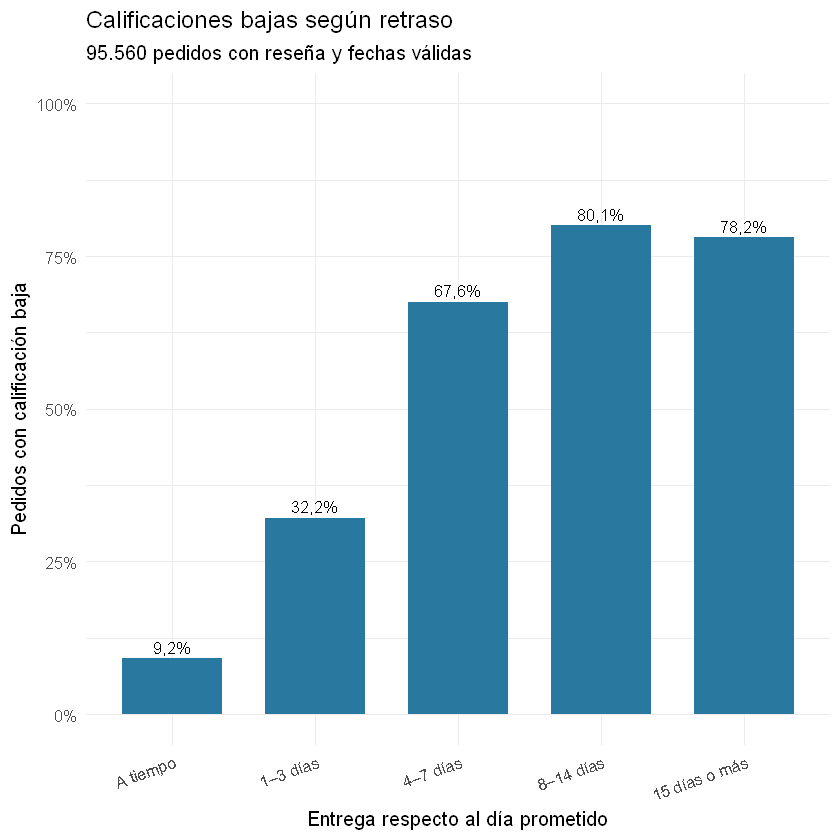

In [17]:
base_analitica <- base_analitica %>% mutate(
  tramo_retraso = cut(desfase_dias, breaks = c(-Inf, 0, 3, 7, 14, Inf),
    labels = c("A tiempo", "1–3 días", "4–7 días", "8–14 días", "15 días o más")))
por_retraso <- resumir_grupo(base_analitica, "tramo_retraso")
mostrar(por_retraso %>% select(tramo_retraso, pedidos, bajas, tasa_bajas, nota_media))
g_retraso <- ggplot(por_retraso, aes(tramo_retraso, tasa_bajas)) +
  geom_col(fill = "#2878A0", width = .7) +
  geom_text(aes(label = porcentaje(tasa_bajas)), vjust = -.4, size = 3.5) +
  scale_y_continuous(labels = label_percent(), limits = c(0, 1)) +
  labs(title = "Calificaciones bajas según retraso", subtitle = paste(numero(N, 0), "pedidos con reseña y fechas válidas"),
       x = "Entrega respecto al día prometido", y = "Pedidos con calificación baja") +
  theme(axis.text.x = element_text(angle = 20, hjust = 1))
guardar_grafico(g_retraso, "01_retraso_satisfaccion", 10, 5.5)
cuota_bajas_puntuales <- sum(!base_analitica$tardia & base_analitica$calificacion_baja) / MALAS
cat("De todas las reseñas bajas, corresponden a pedidos puntuales:", porcentaje(cuota_bajas_puntuales), "\n")

## 10. Distancia y satisfacción: primera evaluación de la hipótesis

Si la distancia fuera un factor relevante, esperaríamos tiempos de entrega más largos y posiblemente más incidentes en trayectos largos. Comparamos tramos para observar el patrón; no imponemos que la tasa tenga que crecer de manera continua.

Se muestran el número de pedidos, la mediana de días de entrega y las tasas de retraso y reseña baja. La distancia ausente se informa aparte y no aparece como cero kilómetros. Los tramos no tienen el mismo ancho: se utilizan para comparar tasas, no para representar una densidad geográfica.

 tramo_distancia pedidos entrega_mediana_dias tasa_tardios tasa_bajas
           0–100   17619                5.082      0.04444     0.1018
         100–300   13163                8.185      0.05113     0.1065
         300–600   30955               10.311      0.06684     0.1343
        600–1000   17658               12.487      0.07039     0.1341
       1000–1500    6507               14.869      0.08621     0.1506
       1500–2500    7775               17.392      0.11653     0.1595
     Más de 2500     829               21.061      0.09409     0.1713
            <NA>    1054               10.894      0.06167     0.1044


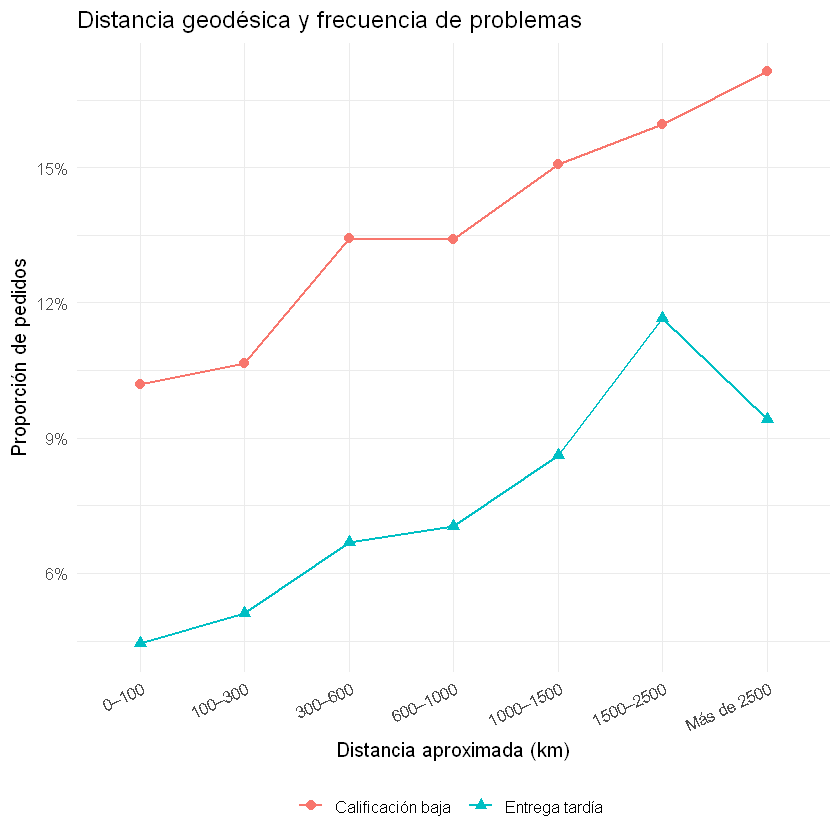

In [18]:
base_analitica <- base_analitica %>% mutate(
  tramo_distancia = cut(distancia_km, breaks = c(-.001, 100, 300, 600, 1000, 1500, 2500, Inf),
    labels = c("0–100", "100–300", "300–600", "600–1000", "1000–1500", "1500–2500", "Más de 2500")))
por_distancia <- resumir_grupo(base_analitica, "tramo_distancia") %>% left_join(
  base_analitica %>% group_by(tramo_distancia) %>% summarise(
    entrega_mediana_dias = median(dias_entrega), .groups = "drop"),
  by = "tramo_distancia", relationship = "one-to-one")
mostrar(por_distancia %>% select(tramo_distancia, pedidos, entrega_mediana_dias, tasa_tardios, tasa_bajas))
datos_distancia <- por_distancia %>% filter(!is.na(tramo_distancia)) %>%
  select(tramo_distancia, tasa_bajas, tasa_tardios) %>%
  pivot_longer(c(tasa_bajas, tasa_tardios), names_to = "indicador", values_to = "tasa") %>%
  mutate(indicador = recode(indicador, tasa_bajas = "Calificación baja", tasa_tardios = "Entrega tardía"))
g_distancia <- ggplot(datos_distancia, aes(tramo_distancia, tasa, group = indicador,
                                          colour = indicador, shape = indicador)) +
  geom_line(linewidth = .8) + geom_point(size = 2.5) +
  scale_y_continuous(labels = label_percent()) +
  labs(title = "Distancia geodésica y frecuencia de problemas", x = "Distancia aproximada (km)",
       y = "Proporción de pedidos", colour = NULL, shape = NULL) +
  theme(axis.text.x = element_text(angle = 25, hjust = 1), legend.position = "bottom")
guardar_grafico(g_distancia, "02_distancia_problemas", 10, 5.5)

### 10.1 Correlaciones a nivel de pedido

Spearman compara el orden relativo de valores y no requiere una relación lineal. Una correlación positiva con días de entrega significa que notas o duraciones tienden a crecer juntas; una negativa con la nota indica que una mayor duración se asocia con peor calificación.

Mostramos el número de pares completos y el coeficiente. Con muestras grandes, un valor p pequeño puede acompañar una asociación muy débil. Por eso interpretamos el tamaño de `rho`, no solo la significación. Los valores p son exploratorios y no están ajustados por múltiples comparaciones.

In [19]:
correlacion_par <- function(df, x, y) {
  pares <- df %>% select(all_of(c(x, y))) %>% filter(if_all(everything(), ~ !is.na(.x)))
  if (nrow(pares) < 3 || n_distinct(pares[[x]]) < 2 || n_distinct(pares[[y]]) < 2) {
    return(tibble(variable = x, resultado = y, pares = nrow(pares), rho = NA_real_, p = NA_real_))
  }
  prueba <- suppressWarnings(cor.test(pares[[x]], pares[[y]], method = "spearman", exact = FALSE))
  tibble(variable = x, resultado = y, pares = nrow(pares), rho = unname(prueba$estimate), p = prueba$p.value)
}
variables_pedido <- c("distancia_km", "desfase_dias", "dias_entrega", "preparacion_dias",
                      "transito_dias", "valor_productos", "flete", "flete_relativo", "n_items", "cuotas")
correlaciones_pedido <- map_dfr(variables_pedido, ~ correlacion_par(base_analitica, .x, "satisfaccion"))
correlaciones_logisticas <- bind_rows(
  correlacion_par(base_analitica, "distancia_km", "dias_entrega"),
  correlacion_par(base_analitica, "distancia_km", "transito_dias"),
  correlacion_par(base_analitica, "distancia_km", "preparacion_dias"))
mostrar(correlaciones_pedido %>% arrange(rho))
mostrar(correlaciones_logisticas)

         variable    resultado pares      rho       p
     dias_entrega satisfaccion 95560 -0.23467 <0.0001
    transito_dias satisfaccion 95540 -0.19598 <0.0001
     desfase_dias satisfaccion 95560 -0.17706 <0.0001
          n_items satisfaccion 95560 -0.10775 <0.0001
 preparacion_dias satisfaccion 94202 -0.10405 <0.0001
            flete satisfaccion 95560 -0.08859 <0.0001
     distancia_km satisfaccion 94506 -0.06791 <0.0001
   flete_relativo satisfaccion 95560 -0.03082 <0.0001
  valor_productos satisfaccion 95560 -0.02926 <0.0001
           cuotas satisfaccion 95560 -0.02144 <0.0001
     variable        resultado pares     rho       p
 distancia_km     dias_entrega 94506 0.54318 <0.0001
 distancia_km    transito_dias 94486 0.61618 <0.0001
 distancia_km preparacion_dias 93167 0.01818 <0.0001


## 11. Regiones y estados del cliente

La región corresponde al destino del pedido. Separamos dos preguntas: **dónde hay más casos** y **dónde la tasa es mayor**. Una región con muchas ventas puede concentrar incidentes sin tener la peor tasa.

Para el ranking de tasas por estado exigimos al menos 500 pedidos. Este umbral permite una lectura más estable; el Pareto territorial, en cambio, conserva los 27 destinos. Las diferencias no permiten inferir actitudes culturales ni identificar al transportista responsable.

       region pedidos bajas tardios ambos nota_media distancia_mediana_km preparacion_mediana_dias
     Nordeste    8947  1502    1121   728      3.968               1876.1                    1.898
        Norte    1774   270     148    98      4.029               2366.1                    1.872
 Centro-Oeste    5580   728     361   231      4.129                860.8                    1.816
      Sudeste   65560  8077    3949  2443      4.181                329.8                    1.828
          Sur   13699  1615     799   477      4.192                627.7                    1.876
 transito_mediano_dias tasa_bajas tasa_tardios tasa_ambos cuota_casos_conjuntos
                14.017     0.1679      0.12529    0.08137               0.18305
                16.357     0.1522      0.08343    0.05524               0.02464
                10.207     0.1305      0.06470    0.04140               0.05808
                 5.993     0.1232      0.06023    0.03726               0.61428
      

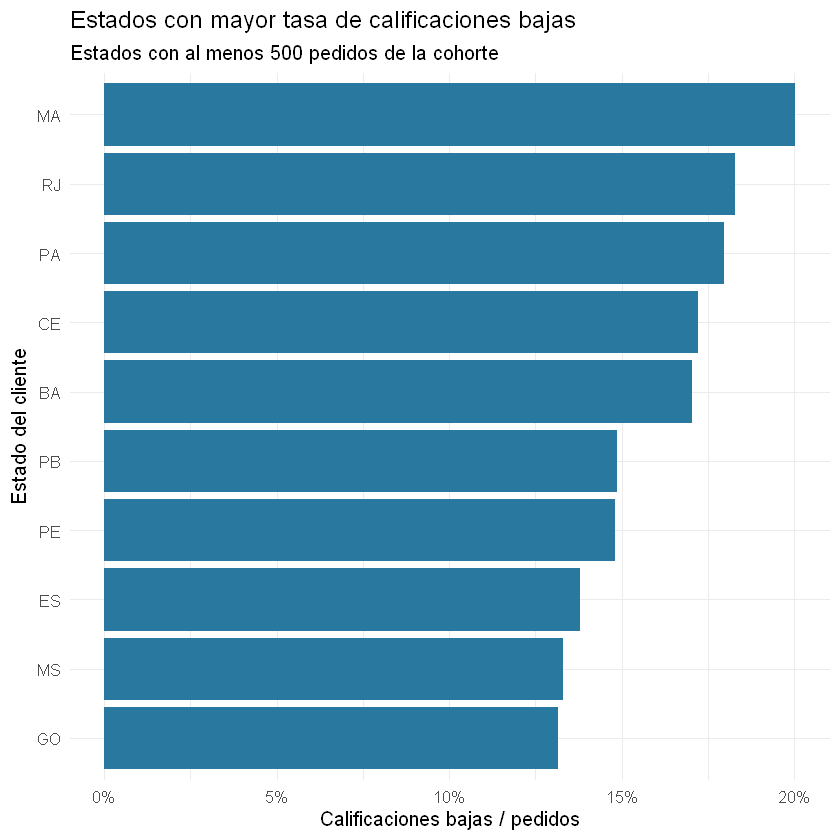

In [20]:
regiones <- list(Norte = c("AC", "AM", "AP", "PA", "RO", "RR", "TO"),
  Nordeste = c("AL", "BA", "CE", "MA", "PB", "PE", "PI", "RN", "SE"),
  `Centro-Oeste` = c("DF", "GO", "MS", "MT"), Sudeste = c("ES", "MG", "RJ", "SP"),
  Sur = c("PR", "RS", "SC"))
mapa_region <- purrr::imap_dfr(regiones, ~ tibble(customer_state = .x, region = .y))
base_analitica <- base_analitica %>% left_join(mapa_region, by = "customer_state", relationship = "many-to-one")
por_region <- resumir_grupo(base_analitica, "region") %>% mutate(cuota_casos_conjuntos = ambos / CONJUNTOS)
por_estado <- resumir_grupo(base_analitica, "customer_state")
mostrar(por_region %>% arrange(desc(tasa_bajas)))
estados_comparables <- por_estado %>% filter(pedidos >= 500) %>% arrange(desc(tasa_bajas))
mostrar(estados_comparables %>% select(customer_state, pedidos, tasa_bajas, tasa_tardios, ambos, distancia_mediana_km), 10)
g_estados <- estados_comparables %>% slice_head(n = 10) %>%
  ggplot(aes(reorder(customer_state, tasa_bajas), tasa_bajas)) +
  geom_col(fill = "#2878A0") + coord_flip() +
  scale_y_continuous(labels = label_percent()) +
  labs(title = "Estados con mayor tasa de calificaciones bajas", subtitle = "Estados con al menos 500 pedidos de la cohorte",
       x = "Estado del cliente", y = "Calificaciones bajas / pedidos")
guardar_grafico(g_estados, "03_estados_tasa_baja", 9, 6)

## 12. Categorías: intensidad y volumen de casos

Cada pedido participa una vez en cada categoría distinta que contiene. Por eso los totales de este ranking pueden superponerse. La calificación pertenece al pedido, no necesariamente al producto de una categoría particular.

La columna `categoria` conserva el nombre original portugués para poder contrastar con los CSV. Se añade la traducción inglesa disponible. El gráfico presenta tasas entre categorías de al menos 500 pedidos; más adelante el Pareto utilizará reparto fraccional para ser sumable.

                         categoria   product_category_name_english pedidos tasa_bajas tasa_tardios ambos
                 moveis_escritorio                office_furniture    1239     0.2171      0.07990    61
                     sin_categoria                            <NA>    1380     0.1739      0.07246    69
                   cama_mesa_banho                  bed_bath_table    9172     0.1590      0.07283   430
                  moveis_decoracao                 furniture_decor    6212     0.1528      0.07083   269
            informatica_acessorios           computers_accessories    6486     0.1446      0.06260   249
                             bebes                            baby    2778     0.1425      0.07919   148
                         telefonia                       telephony    4062     0.1413      0.07065   160
                relogios_presentes                   watches_gifts    5448     0.1369      0.07250   247
 construcao_ferramentas_construcao construction_tools_c

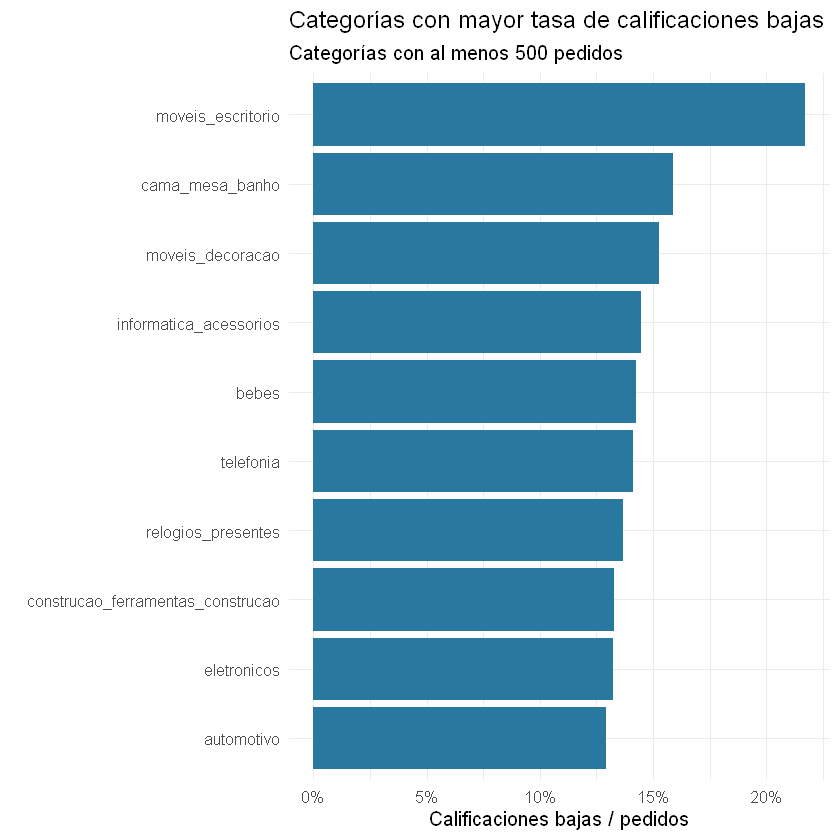

In [21]:
base_categoria <- base_analitica %>% inner_join(puente_categoria, by = "order_id", relationship = "one-to-many")
por_categoria <- resumir_grupo(base_categoria, "categoria") %>% left_join(
  translation, by = c("categoria" = "product_category_name"), relationship = "many-to-one")
mostrar(por_categoria %>% filter(pedidos >= 500) %>% arrange(desc(tasa_bajas)) %>%
  select(categoria, product_category_name_english, pedidos, tasa_bajas, tasa_tardios, ambos), 12)
g_categorias <- por_categoria %>% filter(pedidos >= 500, categoria != "sin_categoria") %>%
  slice_max(tasa_bajas, n = 10, with_ties = FALSE) %>%
  ggplot(aes(reorder(categoria, tasa_bajas), tasa_bajas)) + geom_col(fill = "#2878A0") + coord_flip() +
  scale_y_continuous(labels = label_percent()) +
  labs(title = "Categorías con mayor tasa de calificaciones bajas", subtitle = "Categorías con al menos 500 pedidos",
       x = NULL, y = "Calificaciones bajas / pedidos")
guardar_grafico(g_categorias, "04_categorias_tasa_baja", 10, 6)

## 13. Indicadores por vendedor

El puente pedido–vendedor evita contar varias veces la misma reseña porque el vendedor tenga varios artículos en una orden. Cuando un pedido tiene varios vendedores, aparecerá una vez en cada uno: los rankings son descriptivos y sus totales **no se deben sumar**.

Además de la tasa, calculamos un intervalo de Wilson del 95%. Un vendedor con pocos pedidos puede tener una tasa extrema y mucha incertidumbre. El intervalo describe incertidumbre binomial de la proporción; no corrige diferencias de categoría, región o período ni dependencia entre pedidos.

In [22]:
base_vendedor <- base_analitica %>% inner_join(puente_vendedor,
  by = "order_id", relationship = "one-to-many")
stopifnot(!anyDuplicated(base_vendedor[c("order_id", "seller_id")]))
tabla_vendedores <- resumir_grupo(base_vendedor, "seller_id") %>% left_join(
  base_vendedor %>% group_by(seller_id) %>% summarise(
    proporcion_varios_items = mean(n_items > 1), .groups = "drop"),
  by = "seller_id", relationship = "one-to-one") %>% left_join(
  sellers %>% select(seller_id, seller_state, seller_city), by = "seller_id", relationship = "one-to-one")
z <- qnorm(.975)
tabla_vendedores <- tabla_vendedores %>% mutate(
  denominador_wilson = 1 + z^2 / pedidos,
  centro_wilson = (tasa_bajas + z^2 / (2 * pedidos)) / denominador_wilson,
  margen_wilson = z * sqrt(tasa_bajas * (1 - tasa_bajas) / pedidos + z^2 / (4 * pedidos^2)) / denominador_wilson,
  ic95_inferior = centro_wilson - margen_wilson, ic95_superior = centro_wilson + margen_wilson) %>%
  select(-denominador_wilson, -centro_wilson, -margen_wilson)
solo_vendedor <- resumir_grupo(base_vendedor %>% filter(n_vendedores == 1), "seller_id") %>%
  select(seller_id, pedidos_solo = pedidos, tasa_bajas_solo = tasa_bajas)
tabla_vendedores <- tabla_vendedores %>% left_join(solo_vendedor,
  by = "seller_id", relationship = "one-to-one")
mostrar(tabla_vendedores %>% filter(pedidos >= 500) %>% arrange(desc(tasa_bajas)) %>%
  select(seller_id, pedidos, tasa_bajas, ic95_inferior, ic95_superior, tasa_tardios, preparacion_mediana_dias), 10)

                        seller_id pedidos tasa_bajas ic95_inferior ic95_superior tasa_tardios preparacion_mediana_dias
 7c67e1448b00f6e969d365cea6b010ab     967     0.2544        0.2280        0.2828      0.08997                  10.9743
 d2374cbcbb3ca4ab1086534108cc3ab7     509     0.1945        0.1625        0.2311      0.05305                   3.6592
 cca3071e3e9bb7d12640c9fbe2301306     680     0.1882        0.1606        0.2193      0.04706                   2.7747
 4a3ca9315b744ce9f8e9374361493884    1753     0.1843        0.1668        0.2031      0.09698                   1.8507
 7d13fca15225358621be4086e1eb0964     555     0.1712        0.1421        0.2047      0.11532                   3.0929
 1025f0e2d44d7041d6cf58b6550e0bfa     902     0.1674        0.1445        0.1932      0.07871                   3.0561
 6560211a19b47992c3666cc44a7e94c0    1805     0.1607        0.1444        0.1783      0.05263                   0.9222
 ea8482cd71df3c1969d7b9473ff13abc    1126     0.

### 13.1 Buscar vendedores con un patrón parecido

Aplicamos una regla explícita: volumen mínimo, preparación mediana de al menos cinco días y tasa baja superior a la global. Este filtro genera **candidatos a revisión**, no un diagnóstico confirmado.

La tabla también muestra el resultado restringido a pedidos de un solo vendedor. Si la tasa cambia mucho al quitar los pedidos mixtos, debemos ser especialmente prudentes al asignar responsabilidad.

In [23]:
vendedores_similares <- tabla_vendedores %>% filter(
  pedidos >= min_pedidos_correlacion, preparacion_mediana_dias >= umbral_preparacion_dias,
  tasa_bajas > tasa_global) %>% arrange(desc(bajas))
mostrar(vendedores_similares %>% select(seller_id, pedidos, bajas, tasa_bajas,
  preparacion_mediana_dias, transito_mediano_dias, distancia_mediana_km, pedidos_solo, tasa_bajas_solo))

                        seller_id pedidos bajas tasa_bajas preparacion_mediana_dias transito_mediano_dias
 7c67e1448b00f6e969d365cea6b010ab     967   246     0.2544                   10.974                 7.238
 2eb70248d66e0e3ef83659f71b244378     184    87     0.4728                    9.434                 5.524
 88460e8ebdecbfecb5f9601833981930     245    74     0.3020                    5.909                 7.223
 1ca7077d890b907f89be8c954a02686a     107    64     0.5981                    5.623                 7.762
 92eb0f42c21942b6552362b9b114707d     332    47     0.1416                    5.086                 6.664
 213b25e6f54661939f11710a6fddb871     151    31     0.2053                    8.119                 6.239
 dd7ddc04e1b6c2c614352b383efe2d36     120    22     0.1833                    6.157                 5.839
 79ebd9a61bac3eaf882805ed4ecfa12a     133    18     0.1353                    5.393                 8.022
 distancia_mediana_km pedidos_solo tasa_bajas_

## 14. Aporte del vendedor seleccionado al resultado global

No basta con saber que un vendedor tiene una tasa alta. Debemos medir cuánto pesa en el total. Calculamos su participación en pedidos, su participación en reseñas bajas y el cambio de los indicadores globales al excluir los pedidos donde participa.

La exclusión elimina la **unión de sus pedidos**, incluso los compartidos, y cuenta cada orden una sola vez. No prueba que ese vendedor haya causado todas las malas experiencias de esos pedidos.

Una diferencia entre 12,8% y 12,7% se expresa en **puntos porcentuales**, no como una reducción de diez puntos ni como una mejora automáticamente alcanzable.

In [24]:
pedidos_objetivo <- base_vendedor %>% filter(seller_id == vendedor_objetivo)
if (nrow(pedidos_objetivo) == 0) stop("El vendedor objetivo no está en la cohorte seleccionada.")
resto_pedidos <- base_analitica %>% anti_join(pedidos_objetivo %>% select(order_id), by = "order_id")
stopifnot(nrow(pedidos_objetivo) + nrow(resto_pedidos) == N)
tasa_resto <- mean(resto_pedidos$calificacion_baja)
impacto <- tibble(indicador = c("Pedidos donde participa", "Reseñas bajas en esos pedidos",
  "Cuota de pedidos global", "Cuota de reseñas bajas global", "Tasa propia", "Tasa del resto",
  "Tasa global actual", "Tasa global al excluir sus pedidos", "Cambio global en puntos porcentuales",
  "Nota media global actual", "Nota media al excluir sus pedidos"),
  valor = c(nrow(pedidos_objetivo), sum(pedidos_objetivo$calificacion_baja),
    nrow(pedidos_objetivo) / N, sum(pedidos_objetivo$calificacion_baja) / MALAS,
    mean(pedidos_objetivo$calificacion_baja), tasa_resto, tasa_global, tasa_resto,
    100 * (tasa_global - tasa_resto), mean(base_analitica$satisfaccion), mean(resto_pedidos$satisfaccion)))
mostrar(impacto)

                            indicador     valor
              Pedidos donde participa 967.00000
        Reseñas bajas en esos pedidos 246.00000
              Cuota de pedidos global   0.01012
        Cuota de reseñas bajas global   0.02018
                          Tasa propia   0.25440
                       Tasa del resto   0.12629
                   Tasa global actual   0.12758
   Tasa global al excluir sus pedidos   0.12629
 Cambio global en puntos porcentuales   0.12963
             Nota media global actual   4.15658
    Nota media al excluir sus pedidos   4.16333


### 14.1 Escenario descriptivo: igualar la tasa del resto

Ahora mantenemos los pedidos del vendedor y suponemos que su tasa fuera la del resto. La diferencia entre reseñas bajas observadas y las de esta referencia cuantifica una brecha descriptiva.

No es una predicción de reseñas evitables: el vendedor puede vender categorías o atender destinos distintos. El escenario no identifica qué ocurriría después de una intervención.

In [25]:
bajas_objetivo <- sum(pedidos_objetivo$calificacion_baja)
bajas_referencia <- nrow(pedidos_objetivo) * tasa_resto
exceso_descriptivo <- bajas_objetivo - bajas_referencia
reduccion_global_pp <- 100 * exceso_descriptivo / N
mostrar(tibble(observadas = bajas_objetivo, referencia_misma_tasa_resto = bajas_referencia,
  diferencia_descriptiva = exceso_descriptivo, cambio_global_pp = reduccion_global_pp))
cat("Tasa propia:", porcentaje(mean(pedidos_objetivo$calificacion_baja)),
    "| Tasa del resto:", porcentaje(tasa_resto), "\n")

 observadas referencia_misma_tasa_resto diferencia_descriptiva cambio_global_pp
        246                       122.1                  123.9           0.1296
Tasa propia: 25,4% | Tasa del resto: 12,6% 


## 15. Matriz de correlación entre vendedores

### 15.1 Qué observación estamos comparando

Aquí cada fila es **un vendedor**, no un pedido. Correlacionamos su tasa baja con su preparación mediana, tránsito, distancia, tasa tardía, proporción de pedidos con varios artículos y volumen. Exigimos al menos 100 pedidos y damos el mismo peso a cada vendedor.

No correlacionamos el ID: es una etiqueta sin significado numérico. La relación entre nota media y tasa baja es en parte mecánica porque ambas salen de las mismas reseñas. Tampoco debemos trasladar una correlación agregada al comportamiento de una orden individual.

In [26]:
etiquetas_matriz <- c(tasa_bajas = "Calificaciones bajas", nota_media = "Nota media",
  tasa_tardios = "Entregas tardías", preparacion_mediana_dias = "Preparación (días)",
  transito_mediano_dias = "Tránsito (días)", distancia_mediana_km = "Distancia (km)",
  proporcion_varios_items = "Varios artículos", pedidos = "Pedidos")
vendedores_comparables <- tabla_vendedores %>% filter(pedidos >= min_pedidos_correlacion)
if (nrow(vendedores_comparables) < 3) stop("Muy pocos vendedores: revisa el umbral de volumen.")
matriz <- cor(as.data.frame(vendedores_comparables %>% select(all_of(names(etiquetas_matriz)))),
              method = "spearman", use = "pairwise.complete.obs")
pares_matriz <- sapply(names(etiquetas_matriz), function(x) {
  sapply(names(etiquetas_matriz), function(y) sum(complete.cases(vendedores_comparables[c(x, y)])))
})
dimnames(pares_matriz) <- dimnames(matriz)
stopifnot(isTRUE(all.equal(matriz, t(matriz))))
cat("Vendedores incluidos:", nrow(vendedores_comparables), "\n")
print(round(matriz, 3))
cat("Número de vendedores completos para cada par:\n")
print(pares_matriz)

Vendedores incluidos: 207 
                         tasa_bajas nota_media tasa_tardios preparacion_mediana_dias transito_mediano_dias
tasa_bajas                    1.000     -0.956        0.478                    0.387                 0.239
nota_media                   -0.956      1.000       -0.451                   -0.406                -0.252
tasa_tardios                  0.478     -0.451        1.000                    0.355                 0.248
preparacion_mediana_dias      0.387     -0.406        0.355                    1.000                 0.120
transito_mediano_dias         0.239     -0.252        0.248                    0.120                 1.000
distancia_mediana_km         -0.082      0.050       -0.152                   -0.002                 0.598
proporcion_varios_items       0.310     -0.297        0.075                    0.148                -0.074
pedidos                       0.085     -0.092        0.181                    0.131                 0.155
          

### 15.2 Visualizar la matriz e interpretar su magnitud

El mapa de calor muestra el signo y tamaño de Spearman entre −1 y 1. Los valores cercanos a cero indican poca asociación monotónica; valores positivos indican que ambos indicadores tienden a aumentar juntos.

La matriz no controla la mezcla de categoría, región o mes. Para comprobar sensibilidad repetimos las correlaciones con un mínimo de 500 pedidos, aunque ese grupo de vendedores es mucho más pequeño.

Sensibilidad con al menos 500 pedidos: 24 vendedores
           tasa_bajas nota_media tasa_tardios preparacion_mediana_dias transito_mediano_dias distancia_mediana_km
tasa_bajas          1     -0.957        0.348                    0.615                 0.108                0.031
           proporcion_varios_items pedidos
tasa_bajas                   0.438    0.01


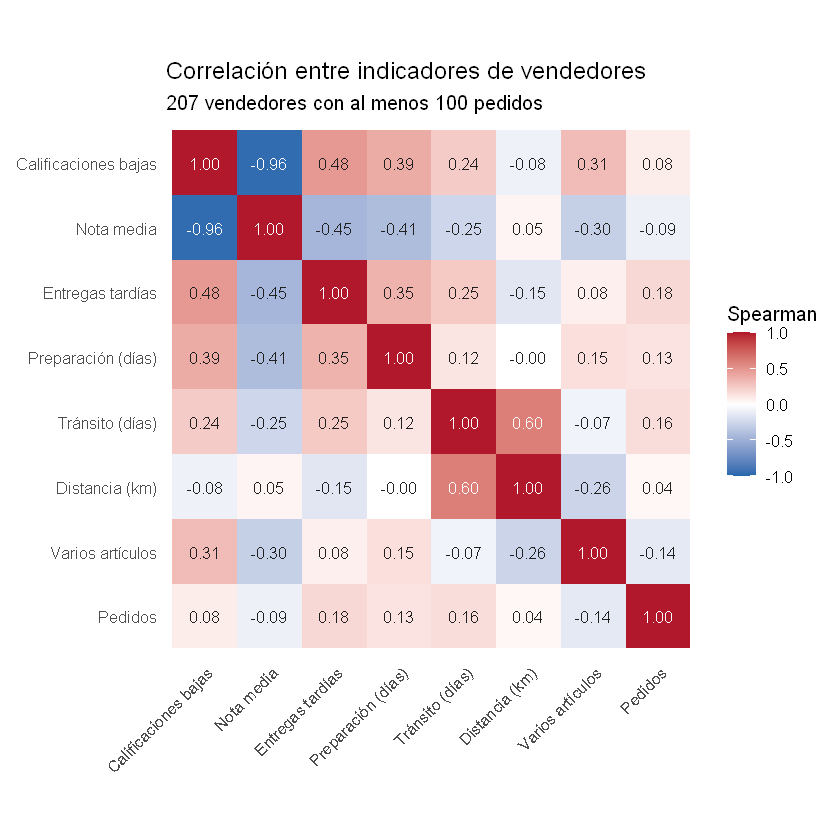

In [27]:
datos_matriz <- as.data.frame(as.table(matriz), responseName = "rho") %>%
  mutate(Var1 = factor(as.character(Var1), levels = names(etiquetas_matriz)),
         Var2 = factor(as.character(Var2), levels = rev(names(etiquetas_matriz))))
g_matriz <- ggplot(datos_matriz, aes(Var1, Var2, fill = rho)) +
  geom_tile() + geom_text(aes(label = sprintf("%.2f", rho), colour = abs(rho) > .55), size = 3.3) +
  scale_colour_manual(values = c(`TRUE` = "white", `FALSE` = "#202020"), guide = "none") +
  scale_fill_gradient2(low = "#2166AC", mid = "white", high = "#B2182B", midpoint = 0,
                       limits = c(-1, 1), name = "Spearman") +
  scale_x_discrete(labels = etiquetas_matriz) + scale_y_discrete(labels = etiquetas_matriz) +
  coord_fixed() + labs(title = "Correlación entre indicadores de vendedores",
    subtitle = paste(nrow(vendedores_comparables), "vendedores con al menos", min_pedidos_correlacion, "pedidos"), x = NULL, y = NULL) +
  theme(axis.text.x = element_text(angle = 45, hjust = 1), panel.grid = element_blank())
guardar_grafico(g_matriz, "05_matriz_vendedores", 11, 8.5)
comparables_500 <- tabla_vendedores %>% filter(pedidos >= 500)
if (nrow(comparables_500) >= 3) {
  matriz_500 <- cor(as.data.frame(comparables_500 %>% select(all_of(names(etiquetas_matriz)))),
                    method = "spearman", use = "pairwise.complete.obs")
  cat("Sensibilidad con al menos 500 pedidos:", nrow(comparables_500), "vendedores\n")
  print(round(matriz_500["tasa_bajas", , drop = FALSE], 3))
}

## 16. Pareto: de la cantidad de casos a una prioridad de revisión

### 16.1 Evitar que un pedido mixto se cuente dos veces

La regla 80–20 es una orientación, no un resultado que debamos forzar. Ordenamos vendedores por cantidad de problemas y calculamos su acumulado real.

Para construir un Pareto sumable, repartimos un pedido problemático por igual entre sus vendedores distintos: si hay dos, cada uno recibe 0,5 casos. Esto conserva el total real. Es una **convención de asignación**, no una conclusión sobre quién causó el problema.

Se calculan dos Pareto distintos: todas las reseñas bajas y los pedidos que además fueron tardíos. El denominador incluye todos los vendedores de la cohorte, aun los que no tienen incidentes.

In [28]:
base_vendedor <- base_vendedor %>% mutate(
  bajas_asignadas = as.numeric(calificacion_baja) / n_vendedores,
  conjuntos_asignados = as.numeric(ambos) / n_vendedores)
asignacion_vendedor <- base_vendedor %>% group_by(seller_id) %>% summarise(
  bajas_asignadas = sum(bajas_asignadas), conjuntos_asignados = sum(conjuntos_asignados), .groups = "drop") %>%
  left_join(tabla_vendedores, by = "seller_id", relationship = "one-to-one")
stopifnot(abs(sum(asignacion_vendedor$bajas_asignadas) - MALAS) < .00000001,
          abs(sum(asignacion_vendedor$conjuntos_asignados) - CONJUNTOS) < .00000001)
cat("Casos conciliados:", MALAS, "reseñas bajas y", CONJUNTOS, "casos conjuntos.\n")

Casos conciliados: 12192 reseñas bajas y 3977 casos conjuntos.


### 16.2 Ordenar, acumular y encontrar el corte del 80%

Cada fila del Pareto contiene posición, casos asignados, participación y participación acumulada. El corte incluye al vendedor con el que se alcanza o supera 80%. El 20% de vendedores se redondea hacia arriba a un número entero.

No ordenamos por tasa. Un vendedor pequeño con 100% de reseñas bajas puede requerir atención, pero no necesariamente concentra suficiente volumen para encabezar un Pareto global.

In [29]:
calcular_pareto <- function(df, clave, medida) {
  p <- df %>% arrange(desc(.data[[medida]]), .data[[clave]])
  total <- sum(p[[medida]])
  if (total <= 0) stop("No hay casos positivos para el Pareto de ", medida)
  p <- p %>% mutate(posicion = row_number(), cuota = .data[[medida]] / total,
                     acumulado = cumsum(cuota), grupos_acumulados = posicion / n())
  n80 <- which(p$acumulado >= .8)[1]
  n20 <- ceiling(.2 * nrow(p))
  estadisticas <- tibble(grupos = nrow(p), casos = total, grupos_para_80 = n80,
    proporcion_grupos_para_80 = n80 / nrow(p), grupos_top20pct = n20,
    cuota_top20pct = sum(head(p$cuota, n20)))
  list(tabla = p, estadisticas = estadisticas)
}
pb <- calcular_pareto(asignacion_vendedor, "seller_id", "bajas_asignadas")
pc <- calcular_pareto(asignacion_vendedor, "seller_id", "conjuntos_asignados")
pareto_bajas <- pb$tabla; pareto_conjuntos <- pc$tabla
mostrar(bind_rows(pb$estadisticas %>% mutate(problema = "Calificación baja"),
                  pc$estadisticas %>% mutate(problema = "Retraso y baja")))
mostrar(pareto_bajas %>% select(posicion, seller_id, pedidos, tasa_bajas,
  bajas_asignadas, acumulado, preparacion_mediana_dias), 20)

 grupos casos grupos_para_80 proporcion_grupos_para_80 grupos_top20pct cuota_top20pct          problema
   2941 12192            427                    0.1452             589         0.8607 Calificación baja
   2941  3977            356                    0.1210             589         0.9003    Retraso y baja
 posicion                        seller_id pedidos tasa_bajas bajas_asignadas acumulado preparacion_mediana_dias
        1 4a3ca9315b744ce9f8e9374361493884    1753     0.1843          301.17   0.02470                   1.8507
        2 6560211a19b47992c3666cc44a7e94c0    1805     0.1607          280.83   0.04774                   0.9222
        3 7c67e1448b00f6e969d365cea6b010ab     967     0.2544          242.83   0.06765                  10.9743
        4 cc419e0650a3c5ba77189a1882b7556a    1647     0.1275          209.00   0.08480                   1.9965
        5 1f50f920176fa81dab994f9023523100    1394     0.1399          184.83   0.09996                   3.3157
        6 

### 16.3 Curvas acumuladas del Pareto

La línea horizontal marca el 80% de los casos y la vertical el 20% de vendedores. El punto identifica el corte observado. La curva es una forma de Pareto por participación acumulada, elegida para no comprimir miles de etiquetas de vendedores en un gráfico de barras.

La figura responde cuántos vendedores concentran el problema histórico; no estima qué proporción se solucionaría al intervenir.

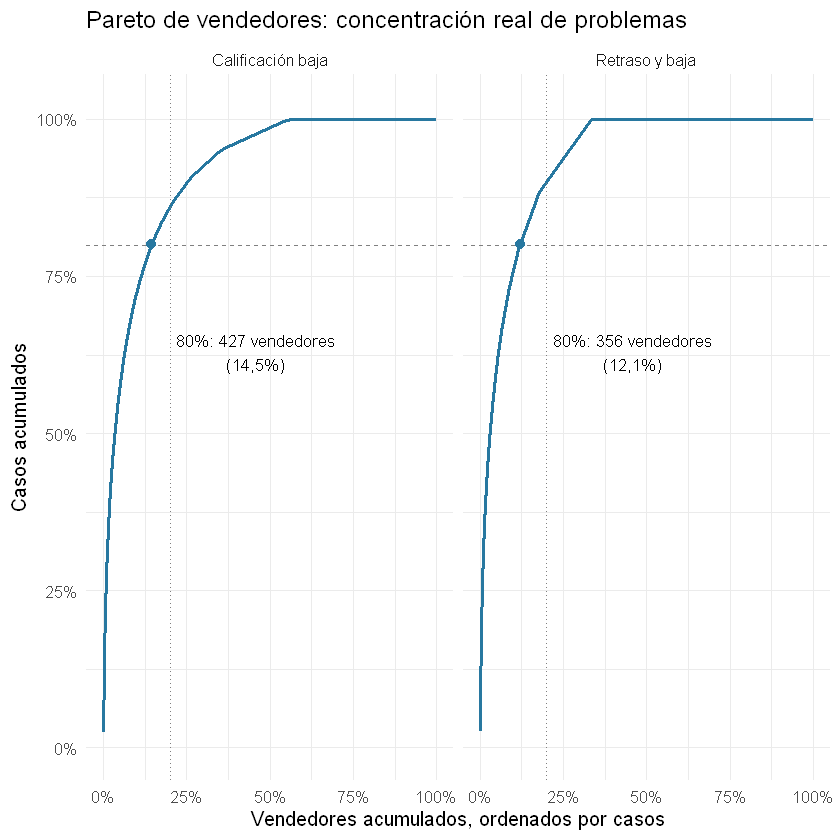

In [30]:
curvas_pareto <- bind_rows(
  pareto_bajas %>% transmute(posicion, grupos_acumulados, acumulado, problema = "Calificación baja"),
  pareto_conjuntos %>% transmute(posicion, grupos_acumulados, acumulado, problema = "Retraso y baja"))
puntos_80 <- bind_rows(
  pareto_bajas[pb$estadisticas$grupos_para_80, ] %>% mutate(problema = "Calificación baja"),
  pareto_conjuntos[pc$estadisticas$grupos_para_80, ] %>% mutate(problema = "Retraso y baja")) %>%
  mutate(etiqueta = paste0("80%: ", posicion, " vendedores\n(", porcentaje(grupos_acumulados), ")"))
g_pareto <- ggplot(curvas_pareto, aes(grupos_acumulados, acumulado)) +
  geom_line(colour = "#2878A0", linewidth = .9) +
  geom_hline(yintercept = .8, linetype = "dashed", colour = "grey50") +
  geom_vline(xintercept = .2, linetype = "dotted", colour = "grey50") +
  geom_point(data = puntos_80, size = 2.5, colour = "#2878A0") +
  geom_text(data = puntos_80, aes(x = .46, y = .63, label = etiqueta), size = 3.5) +
  facet_wrap(~ problema) +
  scale_x_continuous(labels = label_percent(), limits = c(0, 1)) +
  scale_y_continuous(labels = label_percent(), limits = c(0, 1.02)) +
  labs(title = "Pareto de vendedores: concentración real de problemas",
    x = "Vendedores acumulados, ordenados por casos", y = "Casos acumulados")
guardar_grafico(g_pareto, "06_pareto_vendedores", 12, 5.5)

## 17. Una lista manejable: 10, 20, 50 o 100 vendedores

El corte del 80% puede contener cientos de vendedores. Para dimensionar una primera revisión calculamos el volumen cubierto por listas más pequeñas.

Mostramos dos medidas distintas: participación de **casos asignados**, que es sumable, y **reseñas bajas únicas de pedidos donde participan**, que incluye completos los pedidos compartidos. La segunda puede ser mayor. No se suman coberturas entre listas ni se interpreta cobertura como solución asegurada.

In [31]:
tam_listas <- unique(pmin(c(10L, 20L, 50L, 100L, pb$estadisticas$grupos_para_80), nrow(pareto_bajas)))
cobertura_listas <- map_dfr(tam_listas, function(k) {
  seleccion <- head(pareto_bajas$seller_id, k)
  ordenes <- puente_vendedor %>% filter(seller_id %in% seleccion) %>% distinct(order_id)
  cubiertos <- base_analitica %>% semi_join(ordenes, by = "order_id")
  tibble(vendedores = k, cuota_asignada = sum(head(pareto_bajas$cuota, k)),
    pedidos_unicos = nrow(cubiertos), bajas_unicas = sum(cubiertos$calificacion_baja),
    cuota_bajas_unicas = sum(cubiertos$calificacion_baja) / MALAS)
})
mostrar(cobertura_listas)
posicion_objetivo <- pareto_bajas %>% filter(seller_id == vendedor_objetivo) %>% pull(posicion)
cat("Posición del vendedor seleccionado en el Pareto:", posicion_objetivo, "\n")

 vendedores cuota_asignada pedidos_unicos bajas_unicas cuota_bajas_unicas
         10         0.1586          12927         2004             0.1644
         20         0.2375          19778         2994             0.2456
         50         0.3753          31449         4693             0.3849
        100         0.4985          41215         6202             0.5087
        427         0.8004          70134         9864             0.8091
Posición del vendedor seleccionado en el Pareto: 3 


## 18. Pareto de categorías y estados

Los mismos incidentes pueden verse desde tres dimensiones: vendedor, categoría y destino. Para categorías se reparte cada caso entre categorías distintas del pedido; para estados no se necesita reparto porque cada pedido tiene un único estado de destino.

Estas vistas son complementarias y se superponen. No sumamos sus participaciones para estimar un beneficio total. El grupo `sin_categoria`, si aparece, se conserva como ausencia de clasificación, no como una categoría de producto conocida.

In [32]:
base_categoria <- base_categoria %>% group_by(order_id) %>% mutate(
  n_grupos_categoria = n(), bajas_asignadas = as.numeric(calificacion_baja) / n_grupos_categoria) %>% ungroup()
asignacion_categoria <- base_categoria %>% group_by(categoria) %>%
  summarise(bajas_asignadas = sum(bajas_asignadas), .groups = "drop")
stopifnot(abs(sum(asignacion_categoria$bajas_asignadas) - MALAS) < .00000001)
pcat <- calcular_pareto(asignacion_categoria, "categoria", "bajas_asignadas")
pest <- calcular_pareto(por_estado, "customer_state", "bajas")
pareto_categorias <- pcat$tabla; pareto_estados <- pest$tabla
mostrar(bind_rows(pcat$estadisticas %>% mutate(dimension = "Categorías"),
                  pest$estadisticas %>% mutate(dimension = "Estados")))
mostrar(pareto_categorias %>% select(posicion, categoria, bajas_asignadas, acumulado), 16)
mostrar(pareto_estados %>% select(posicion, customer_state, pedidos, bajas, acumulado), 10)

 grupos casos grupos_para_80 proporcion_grupos_para_80 grupos_top20pct cuota_top20pct  dimension
     74 12192             16                    0.2162              15         0.7980 Categorías
     27 12192              7                    0.2593               6         0.7804    Estados
 posicion              categoria bajas_asignadas acumulado
        1        cama_mesa_banho          1419.3    0.1164
        2           beleza_saude           961.0    0.1952
        3 informatica_acessorios           929.3    0.2715
        4       moveis_decoracao           906.2    0.3458
        5          esporte_lazer           834.3    0.4142
        6     relogios_presentes           736.3    0.4746
        7  utilidades_domesticas           645.2    0.5275
        8              telefonia           567.3    0.5741
        9             automotivo           479.3    0.6134
       10             brinquedos           417.0    0.6476
       11     ferramentas_jardim           399.7    0.6804
 

## 19. Comprobaciones de sensibilidad

### 19.1 Promedio, primera y última reseña

Comparamos las tres reglas sobre los mismos pedidos analizados. Esto permite ver si las conclusiones dependen de cómo se resuelven las reseñas múltiples. No volvemos a cambiar la ventana ni el denominador durante esta comparación.

Una media de 2,5 no se clasifica como baja porque la definición acordada es satisfacción ≤ 2. Las reglas se informan junto al resultado para poder comparar versiones del trabajo.

In [33]:
sensibilidad_resenas <- tibble(
  regla = c("Promedio de reseñas", "Primera reseña", "Última reseña"),
  pedidos = N, tasa_bajas = c(mean(base_analitica$nota_promedio <= 2),
    mean(base_analitica$nota_primera <= 2), mean(base_analitica$nota_ultima <= 2)))
mostrar(sensibilidad_resenas %>% mutate(porcentaje = porcentaje(tasa_bajas)))

               regla pedidos tasa_bajas porcentaje
 Promedio de reseñas   95560     0.1276      12,8%
      Primera reseña   95560     0.1279      12,8%
       Última reseña   95560     0.1280      12,8%


### 19.2 Cuándo respondió el cliente

Un pedido entregado al cierre de la base puede haber recibido la reseña cuando el cliente todavía esperaba. Comparamos tasas según la última respuesta sea anterior o posterior a la entrega registrada.

Esta es una comprobación temporal. Con promedio de reseñas, la última respuesta no representa todas las opiniones de ese pedido. Excluir respuestas anteriores también selecciona una población distinta, por lo que no elimina todos los sesgos.

In [34]:
sensibilidad_momento <- base_analitica %>% mutate(momento = if_else(
  respuesta_antes_entrega, "Última respuesta antes de entrega", "Última respuesta posterior o igual")) %>%
  resumir_grupo("momento")
mostrar(sensibilidad_momento %>% select(momento, pedidos, tasa_bajas, tasa_tardios))

                            momento pedidos tasa_bajas tasa_tardios
  Última respuesta antes de entrega    4648    0.78227      0.96192
 Última respuesta posterior o igual   90912    0.09411      0.02098


### 19.3 Solo pedidos de un vendedor

Repetimos el Pareto en una población donde no hay que repartir reseñas entre vendedores. Si la concentración se mantiene, no depende exclusivamente de la convención de asignación fraccional. El denominador cambia y se informa por separado.

In [35]:
asignacion_solo <- base_vendedor %>% filter(n_vendedores == 1) %>% group_by(seller_id) %>%
  summarise(bajas = sum(calificacion_baja), .groups = "drop")
ps <- calcular_pareto(asignacion_solo, "seller_id", "bajas")
mostrar(ps$estadisticas)
mostrar(tabla_vendedores %>% filter(seller_id %in% vendedores_similares$seller_id) %>%
  select(seller_id, pedidos, tasa_bajas, pedidos_solo, tasa_bajas_solo))

 grupos casos grupos_para_80 proporcion_grupos_para_80 grupos_top20pct cuota_top20pct
   2922 11598            420                    0.1437             585         0.8626
                        seller_id pedidos tasa_bajas pedidos_solo tasa_bajas_solo
 1ca7077d890b907f89be8c954a02686a     107     0.5981          105         0.60000
 213b25e6f54661939f11710a6fddb871     151     0.2053          134         0.12687
 2eb70248d66e0e3ef83659f71b244378     184     0.4728          182         0.47802
 79ebd9a61bac3eaf882805ed4ecfa12a     133     0.1353          122         0.09836
 7c67e1448b00f6e969d365cea6b010ab     967     0.2544          957         0.25078
 88460e8ebdecbfecb5f9601833981930     245     0.3020          226         0.27876
 92eb0f42c21942b6552362b9b114707d     332     0.1416          326         0.13804
 dd7ddc04e1b6c2c614352b383efe2d36     120     0.1833          113         0.17699


## 20. Comparación ajustada opcional del vendedor objetivo

Hasta aquí las comparaciones son descriptivas. Un vendedor puede tener una tasa mayor porque vende otras categorías, atiende destinos distintos o concentra compras en meses difíciles. La regresión logística permite considerar simultáneamente algunos de esos factores.

**Resultado:** calificación baja. **Exposición principal:** participación del vendedor objetivo. **Controles:** categoría, estado del cliente, mes, precio, flete relativo, distancia, varios artículos e intervalos de retraso. Se usan solo pedidos con un vendedor y datos completos. Las categorías con menos de 200 pedidos se agrupan para reducir parámetros con poco volumen.

El modelo estima una **odds ratio**, no una razón directa de probabilidades. Un OR de 2 no significa automáticamente el doble de probabilidad. Los intervalos HC1 son robustos a nivel de pedido, pero no eliminan factores omitidos o dependencia temporal. La exposición es un único vendedor: esto no prueba culpa ni un efecto causal.

La preparación no se añade al ajuste porque puede ser parte del mecanismo que se quiere investigar. Puedes omitir esta sección configurando `ejecutar_modelo <- FALSE`; el Pareto y las correlaciones no dependen de ella.

In [36]:
resultado_modelo <- NULL
if (ejecutar_modelo) {
  datos_modelo <- base_analitica %>% filter(n_vendedores == 1, !is.na(distancia_km)) %>% mutate(
    objetivo = as.integer(vendedor_unico == vendedor_objetivo),
    log_distancia = log2(1 + distancia_km), log_precio = log1p(valor_productos),
    flete_ratio = pmin(flete_relativo, 2), varios_items = as.integer(n_items > 1),
    retraso_1_3 = as.integer(between(desfase_dias, 1, 3)),
    retraso_4_7 = as.integer(between(desfase_dias, 4, 7)),
    retraso_8_14 = as.integer(between(desfase_dias, 8, 14)),
    retraso_15_mas = as.integer(desfase_dias >= 15))
  frecuencia_categoria <- datos_modelo %>% count(categoria_orden, name = "frecuencia_categoria")
  datos_modelo <- datos_modelo %>% left_join(frecuencia_categoria, by = "categoria_orden", relationship = "many-to-one") %>%
    mutate(categoria_modelo = if_else(frecuencia_categoria >= 200, categoria_orden, "otras_menos_200"),
           categoria_modelo = factor(categoria_modelo), customer_state = factor(customer_state), mes = factor(mes)) %>%
    filter(if_all(c(objetivo, log_distancia, log_precio, flete_ratio, categoria_modelo, customer_state, mes), ~ !is.na(.x)))
  if (n_distinct(datos_modelo$objetivo) < 2) {
    cat("Modelo omitido: no existen ambos grupos con datos completos.\n")
  } else {
    cat("Ajustando modelo con", nrow(datos_modelo), "pedidos; del objetivo:", sum(datos_modelo$objetivo), "\n")
    ajuste <- glm(calificacion_baja ~ objetivo + log_distancia + log_precio + flete_ratio + varios_items +
      categoria_modelo + customer_state + mes + retraso_1_3 + retraso_4_7 + retraso_8_14 + retraso_15_mas,
      data = datos_modelo, family = binomial(), control = glm.control(maxit = 60))
    if (!ajuste$converged) stop("El modelo no convergió: no interpretar los coeficientes.")
    covarianza_robusta <- sandwich::vcovHC(ajuste, type = "HC1")
    error_robusto <- sqrt(diag(covarianza_robusta))
    coeficientes <- coef(ajuste)
    variables <- intersect(c("objetivo", "log_distancia", "varios_items", "retraso_1_3",
                             "retraso_4_7", "retraso_8_14", "retraso_15_mas"), names(error_robusto))
    resultado_modelo <- tibble(variable = variables,
      beta = coeficientes[variables], error_estandar = error_robusto[variables],
      OR = exp(beta), IC95_inferior = exp(beta - qnorm(.975) * error_estandar),
      IC95_superior = exp(beta + qnorm(.975) * error_estandar),
      p = 2 * pnorm(-abs(beta / error_estandar)), pedidos_modelo = nrow(datos_modelo))
    mostrar(resultado_modelo)
  }
} else cat("Comparación ajustada omitida por configuración.\n")

Ajustando modelo con 93274 pedidos; del objetivo: 954 
       variable    beta error_estandar     OR IC95_inferior IC95_superior       p pedidos_modelo
       objetivo 0.77226       0.171562  2.165        1.5465         3.030 <0.0001          93274
  log_distancia 0.01344       0.008057  1.014        0.9977         1.030  0.0952          93274
   varios_items 1.04128       0.034860  2.833        2.6457         3.033 <0.0001          93274
    retraso_1_3 1.61274       0.054006  5.017        4.5127         5.577 <0.0001          93274
    retraso_4_7 3.11804       0.055631 22.602       20.2673        25.206 <0.0001          93274
   retraso_8_14 3.74704       0.069614 42.395       36.9882        48.593 <0.0001          93274
 retraso_15_mas 3.59850       0.071327 36.543       31.7757        42.026 <0.0001          93274


## 21. Qué revisar primero: volumen, tasa y etapa operativa

Tomamos los primeros veinte vendedores del Pareto como una primera lista manejable. Después comparamos su tasa con el resultado global y sus tiempos con los umbrales exploratorios.

La columna `hipotesis_a_revisar` no es un diagnóstico automático. Es una guía para solicitar evidencia adicional: fecha de preparación, entrega al operador, ruta, promesa, productos incompletos, devoluciones o atención al cliente. Una preparación corta con muchas malas notas requiere una investigación diferente de una preparación muy larga.

No recomendamos retirar vendedores solo por figurar en un Pareto. La evidencia describe datos históricos y los rankings no están ajustados por composición de pedidos.

In [37]:
acciones_primeros20 <- pareto_bajas %>% slice_head(n = 20) %>% mutate(
  tasa_sobre_global = tasa_bajas > tasa_global,
  hipotesis_a_revisar = case_when(
    preparacion_mediana_dias >= umbral_preparacion_dias ~ "Preparación y entrega al operador",
    transito_mediano_dias >= umbral_transito_dias ~ "Tránsito, ruta y promesa de entrega",
    tasa_tardios > mean(base_analitica$tardia) ~ "Cumplimiento del plazo y mezcla de destinos",
    TRUE ~ "Integridad del pedido, producto y comentarios"))
mostrar(acciones_primeros20 %>% select(posicion, seller_id, pedidos, bajas_asignadas,
  tasa_bajas, tasa_sobre_global, preparacion_mediana_dias, hipotesis_a_revisar))

 posicion                        seller_id pedidos bajas_asignadas tasa_bajas tasa_sobre_global
        1 4a3ca9315b744ce9f8e9374361493884    1753          301.17     0.1843              TRUE
        2 6560211a19b47992c3666cc44a7e94c0    1805          280.83     0.1607              TRUE
        3 7c67e1448b00f6e969d365cea6b010ab     967          242.83     0.2544              TRUE
        4 cc419e0650a3c5ba77189a1882b7556a    1647          209.00     0.1275             FALSE
        5 1f50f920176fa81dab994f9023523100    1394          184.83     0.1399              TRUE
        6 ea8482cd71df3c1969d7b9473ff13abc    1126          158.83     0.1456              TRUE
        7 1025f0e2d44d7041d6cf58b6550e0bfa     902          144.50     0.1674              TRUE
        8 da8622b14eb17ae2831f4ac5b9dab84a    1305          144.00     0.1180             FALSE
        9 4869f7a5dfa277a7dca6462dcf3b52b2    1116          140.50     0.1308              TRUE
       10 8b321bb669392f5163d04c59e235e0

## 22. Conclusiones calculadas a partir de esta ejecución

Las conclusiones siguientes se generan con los datos y la configuración activos. No se escriben manualmente porcentajes tomados de otra cohorte. Si se cambia el perfil, el vendedor o los archivos, se recalculan.

Para presentar al equipo conviene incluir la concentración, una primera lista de revisión y una limitación de interpretación. Un resultado útil debe conectar el indicador con la evidencia que falta para decidir una acción.

In [38]:
rho_distancia <- correlaciones_pedido %>% filter(variable == "distancia_km") %>% pull(rho)
rho_preparacion_vendedor <- matriz["tasa_bajas", "preparacion_mediana_dias"]
estado_volumen <- por_estado %>% arrange(desc(bajas)) %>% slice_head(n = 1)
cuota_primeros20 <- sum(head(pareto_bajas$cuota, 20))
conclusiones <- c(
  paste0("Perfil: ", perfil, "; regla de satisfacción: ", regla_resenas, "."),
  paste0("Se analizaron ", numero(N, 0), " pedidos; ", numero(MALAS, 0), " tienen calificación baja (", porcentaje(tasa_global), ")."),
  paste0("El 80% de casos asignados de reseñas bajas se concentra en ", pb$estadisticas$grupos_para_80,
    " de ", pb$estadisticas$grupos, " vendedores (", porcentaje(pb$estadisticas$proporcion_grupos_para_80), ")."),
  paste0("El 20% superior concentra ", porcentaje(pb$estadisticas$cuota_top20pct), " de esos casos."),
  paste0("La primera lista de 20 vendedores cubre ", porcentaje(cuota_primeros20), " de casos asignados."),
  paste0("El vendedor seleccionado ocupa la posición ", posicion_objetivo,
    "; excluir sus pedidos cambia la tasa global en ", numero(100 * (tasa_global - tasa_resto), 3), " puntos porcentuales."),
  paste0("Spearman entre distancia y satisfacción por pedido: ", numero(rho_distancia, 3),
    "; entre preparación y tasa baja por vendedor: ", numero(rho_preparacion_vendedor, 3), "."),
  paste0("El estado con más reseñas bajas en cantidad es ", estado_volumen$customer_state,
    "; cantidad y tasa no son equivalentes."),
  paste0("El ", porcentaje(cuota_bajas_puntuales), " de las reseñas bajas corresponde a pedidos puntuales; investigar también integridad y producto."),
  "El Pareto indica dónde investigar primero, no quién causó cada problema ni qué porcentaje se resolverá.")
cat(paste0(seq_along(conclusiones), ". ", conclusiones, collapse = "\n"), "\n")

1. Perfil: equipo; regla de satisfacción: promedio.
2. Se analizaron 95.560 pedidos; 12.192 tienen calificación baja (12,8%).
3. El 80% de casos asignados de reseñas bajas se concentra en 427 de 2941 vendedores (14,5%).
4. El 20% superior concentra 86,1% de esos casos.
5. La primera lista de 20 vendedores cubre 23,8% de casos asignados.
6. El vendedor seleccionado ocupa la posición 3; excluir sus pedidos cambia la tasa global en 0,130 puntos porcentuales.
7. Spearman entre distancia y satisfacción por pedido: -0,068; entre preparación y tasa baja por vendedor: 0,387.
8. El estado con más reseñas bajas en cantidad es SP; cantidad y tasa no son equivalentes.
9. El 67,4% de las reseñas bajas corresponde a pedidos puntuales; investigar también integridad y producto.
10. El Pareto indica dónde investigar primero, no quién causó cada problema ni qué porcentaje se resolverá. 


## 23. Verificación final y exportación

Antes de guardar comprobamos de nuevo la unicidad del pedido, los totales del Pareto y el punto donde se alcanza 80%. Se exportan tablas agregadas, gráficos, configuración, conclusiones y versiones. No se exportan comentarios libres ni los datos originales.

Cada perfil utiliza una carpeta independiente. Si se omite el modelo, se elimina únicamente su CSV generado en una ejecución anterior del mismo perfil, para que no se confunda con un ajuste actualizado. Los CSV originales no se modifican.

In [39]:
stopifnot(!anyDuplicated(base_analitica$order_id), nrow(base_analitica) == N,
  abs(sum(pareto_bajas$bajas_asignadas) - MALAS) < .00000001,
  abs(sum(pareto_conjuntos$conjuntos_asignados) - CONJUNTOS) < .00000001,
  abs(sum(pareto_categorias$bajas_asignadas) - MALAS) < .00000001,
  sum(por_estado$pedidos) == N,
  pareto_bajas$acumulado[pb$estadisticas$grupos_para_80] >= .8)
if (pb$estadisticas$grupos_para_80 > 1) {
  stopifnot(pareto_bajas$acumulado[pb$estadisticas$grupos_para_80 - 1] < .8)
}
exportar <- list(diagnostico = diagnostico, nulos_por_columna = nulos_por_columna, filtros = filtros,
  inconsistencias_tiempo = inconsistencias_tiempo, resumen_global = resumen_global,
  por_retraso = por_retraso, por_distancia = por_distancia, por_region = por_region,
  por_estado = por_estado, por_categoria = por_categoria, por_vendedor = tabla_vendedores,
  vendedores_similares = vendedores_similares, impacto_vendedor = impacto,
  correlaciones_pedido = correlaciones_pedido, correlaciones_logisticas = correlaciones_logisticas,
  pareto_vendedores_bajas = pareto_bajas, pareto_vendedores_conjuntos = pareto_conjuntos,
  pareto_categorias = pareto_categorias, pareto_estados = pareto_estados,
  sensibilidad_resenas = sensibilidad_resenas, sensibilidad_momento = sensibilidad_momento,
  pareto_solo_un_vendedor = ps$tabla, cobertura_listas = cobertura_listas,
  acciones_primeros20 = acciones_primeros20)
if (!is.null(resultado_modelo)) exportar$modelo_ajustado <- resultado_modelo else {
  archivo_modelo <- file.path(ruta_salida, "modelo_ajustado.csv")
  if (file.exists(archivo_modelo)) file.remove(archivo_modelo)
}
purrr::iwalk(exportar, function(df, nombre) write_csv(df, file.path(ruta_salida, paste0(nombre, ".csv")), na = ""))
write_csv(as.data.frame(matriz) %>% tibble::rownames_to_column("indicador"),
          file.path(ruta_salida, "matriz_vendedores.csv"))
write_csv(as.data.frame(pares_matriz) %>% tibble::rownames_to_column("indicador"),
          file.path(ruta_salida, "pares_matriz_vendedores.csv"))
configuracion <- list(perfil = perfil, inicio = as.character(fecha_inicio),
  fin_exclusivo = as.character(fecha_fin), regla_resenas = regla_resenas,
  vendedor_objetivo = vendedor_objetivo, min_pedidos_correlacion = min_pedidos_correlacion,
  umbral_preparacion_dias = umbral_preparacion_dias, umbral_transito_dias = umbral_transito_dias,
  fuente = fuente_datos, pedidos = N, bajas = MALAS, conjuntos = CONJUNTOS,
  pareto_bajas = pb$estadisticas, pareto_conjuntos = pc$estadisticas)
jsonlite::write_json(configuracion, file.path(ruta_salida, "configuracion_resultados.json"),
                     pretty = TRUE, auto_unbox = TRUE, na = "null")
writeLines(conclusiones, file.path(ruta_salida, "conclusiones.txt"), useBytes = TRUE)
writeLines(capture.output(sessionInfo()), file.path(ruta_salida, "sessionInfo.txt"))
cat("Verificaciones correctas. Tablas, gráficos y configuración guardados en:\n", ruta_salida, "\n")

Verificaciones correctas. Tablas, gráficos y configuración guardados en:
 ../salidas/pareto_olist_R/equipo 


## 24. Límites y cómo continuar

- **Datos históricos:** describen el período de Olist disponible; no indican el desempeño actual de los vendedores.
- **Unidad de evaluación:** la reseña califica el pedido completo. En órdenes mixtas no conocemos qué vendedor o producto originó la insatisfacción.
- **Geografía aproximada:** se usan zonas postales y no direcciones exactas ni rutas de carretera. No se identifica transportista.
- **Selección de reseñas:** los resultados de satisfacción corresponden a pedidos con nota. La ausencia de reseña no equivale a satisfacción.
- **Momento de respuesta:** algunas opiniones se emiten antes de recibir el pedido. La fecha de la última respuesta es un diagnóstico parcial cuando se promedian reseñas.
- **Asociación y causalidad:** correlaciones, regresión y Pareto ayudan a organizar una investigación. No permiten afirmar cuántos incidentes se evitarían con una medida concreta.
- **Validación operativa:** para decidir acciones hay que revisar incidencias, tiempos de preparación, cumplimiento del operador, productos incompletos y atención al cliente, comparando categorías y destinos semejantes.

La siguiente etapa sería elegir una lista corta, contrastar estos indicadores con evidencia operativa y medir el resultado de una mejora definida. El porcentaje acumulado del Pareto representa concentración de casos, no un porcentaje garantizado de solución.

## Referencias del proyecto

- Repositorio: https://github.com/santiago-1710/Caso-Integrador-Final
- Secuencia de trabajo y criterio por pedido: `notebooks/Pregunta1.ipynb`.
- Referencia de estilo, ventana temporal y satisfacción: `notebooks/Pregunta3_Gustavo.ipynb`.
- Datos originales: Brazilian E-Commerce Public Dataset by Olist, https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce.
- Los resultados de este notebook proceden de los archivos cargados. No se han rellenado con cifras copiadas de la conversación ni de otras páginas.